# <span style="color:#9947dc">HI-Small — Exploratory Data Analysis</span>


### Table of Contents

1. [Load the data](#1-load)
2. [Data quality](#2-data-quality)
3. [Which source file to use](#3-source-selection)
4. [Attaching account details](#4-account-linking)
5. [Checking the labels against the patterns file](#5-pattern-linking)
6. [What a laundering scheme looks like structurally](#6-attempt-structure)
7. [How rare laundering is](#7-target)
8. [Payment format](#8-payment-format)
9. [Transfers within a bank vs between banks](#9-bank-relationship)
10. [Amounts and currencies](#10-amounts)
11. [Behaviour over time](#11-temporal)
12. [Account network structure](#12-network)
13. [Structuring signals](#13-structuring)
14. [Hub accounts](#12b-hubs)
15. [Countries and cross-border flow](#12c-jurisdiction)
16. [Entities](#12d-entities)
17. [Pass-through behaviour](#12e-passthrough)
18. [How long accounts stay active](#12f-lifetime)
19. [Integrity checks](#13b-integrity)
20. [What a laundering attempt actually looks like](#13c-examples)
21. [Can we split the data for training?](#14-leakage)
22. [Findings and handoff](#15-findings)

### 1. Introduction 

This notebook provides a thorough pre-modeling inspection of the HI-Small transaction file from the IBM anti-money-laundering dataset. The primary goal is to uncover the true contents of the data, separate genuine financial signals from artifacts caused by the generation process, and understand underlying patterns before building predictive models.

The analysis covers all 5,078,345 transactions without relying on sampling. Because the file is approximately 400 megabytes in memory, full processing was feasible and necessary to avoid row-ordering biases and sampling artifacts that compromised earlier preliminary versions of this investigation.

### 1.1 Imports 

In [36]:
import warnings
from pathlib import Path
import kagglehub
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display
import eda_utils as eu


### 1.2 Data Loading 

This section details the initial data loading process using the standard IBM anti-money laundering dataset on Kaggle, addressing a critical sorting issue present in the raw files. Because **HI-Small_Trans.csv** is originally ordered by account rather than chronologically, any time-based analysis or temporal validation split requires sorting by timestamp upon ingestion. 

In total, the pipeline ingests 5,078,345 transactions, 518,581 unique accounts, and 3,209 illicit transfers organized into 370 specific laundering attempts, spanning a 17-day observation window from September 1 to September 18, 2022.

In [37]:
# 1. Configurações visuais (usadas pelas células seguintes)
warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 1000)
PURPLE, LILAC = "#9947dc", "#d8b4fe"
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25})

# 2. Download direto do Kaggle
path = kagglehub.dataset_download("ealtman2019/ibm-transactions-for-anti-money-laundering-aml")
data_dir = Path(path)
DATA_DIR = data_dir

# 3. Carregar os CSVs diretamente
trans = pd.read_csv(data_dir / "HI-Small_Trans.csv")
accounts = pd.read_csv(data_dir / "HI-Small_accounts.csv")

print("Transactions shape:", trans.shape)
print("Accounts shape:", accounts.shape)

trans = eu.load_transactions(DATA_DIR / "HI-Small_Trans.csv")
accounts = eu.load_accounts(DATA_DIR / "HI-Small_accounts.csv")
patterns, attempts, malformed = eu.load_patterns(DATA_DIR / "HI-Small_Patterns.txt")

print(f"Transactions      : {len(trans):,} rows x {trans.shape[1]} cols")
print(f"Accounts          : {len(accounts):,} rows x {accounts.shape[1]} cols")
print(f"Pattern transfers : {len(patterns):,} rows in {len(attempts):,} attempts")
print(f"Malformed lines   : {len(malformed)}")
print()
print(f"Timestamp range   : {trans['Timestamp'].min()}  ->  {trans['Timestamp'].max()}")
print(f"Span              : {(trans['Timestamp'].max() - trans['Timestamp'].min()).days} days")
print(f"Sorted by time    : {trans['Timestamp'].is_monotonic_increasing}")
print(f"Memory            : {trans.memory_usage(deep=True).sum() / 1e6:,.0f} MB")

Transactions shape: (5078345, 11)
Accounts shape: (518581, 5)
Transactions      : 5,078,345 rows x 11 cols
Accounts          : 518,581 rows x 5 cols
Pattern transfers : 3,209 rows in 370 attempts
Malformed lines   : 0

Timestamp range   : 2022-09-01 00:00:00  ->  2022-09-18 16:18:00
Span              : 17 days
Sorted by time    : True
Memory            : 894 MB


### 2. Data Quality

This section evaluates data quality across all input files to verify completeness and schema consistency.

In [38]:
summary = pd.DataFrame([
    eu.quality_summary(trans, "HI-Small Transactions"),
    eu.quality_summary(accounts, "HI-Small Accounts"),
    eu.quality_summary(patterns, "HI-Small Patterns"),
]).set_index("Dataset")
display(summary)

print("\nTransactions — column detail")
display(eu.inspect(trans, "Transactions"))

print("\nAccounts — column detail")
display(eu.inspect(accounts, "Accounts"))

,Rows,Columns,Missing cells,Duplicate rows
Dataset,,,,
HI-Small Transactions,5078345,11,0,9
HI-Small Accounts,518581,5,0,0
HI-Small Patterns,3209,14,1355,0



Transactions — column detail


,Data Type,Missing,Missing %,Unique,Sample
Timestamp,datetime64[ns],0,0.0,15018,2022-09-01 00:00:00
From Bank,int64,0,0.0,30470,3209
Account,string,0,0.0,496995,8000F4670
To Bank,int64,0,0.0,15811,3209
Account.1,string,0,0.0,420636,8000F4670
Amount Received,float64,0,0.0,915161,14675.57
Receiving Currency,category,0,0.0,15,US Dollar
Amount Paid,float64,0,0.0,923873,14675.57
Payment Currency,category,0,0.0,15,US Dollar
Payment Format,category,0,0.0,7,Reinvestment



Accounts — column detail


,Data Type,Missing,Missing %,Unique,Sample
Bank Name,string,0,0.0,20053,Portugal Bank #4507
Bank ID,int64,0,0.0,30470,331579
Account Number,string,0,0.0,518573,80B779D80
Entity ID,string,0,0.0,166207,80062E240
Entity Name,string,0,0.0,166207,Sole Proprietorship #50438


Profiling reveals an exceptionally clean dataset with zero missing values in the transaction and account files, and only nine duplicate rows across five million records. Column-level inspection highlights key structural insights, including 496,995 unique senders and 420,636 receivers interacting across thousands of banks, currencies, and payment formats. A total of 518,573 account numbers map to just 166,207 unique entities, showing that single entities frequently operate multiple accounts. Transactions span 15,018 unique timestamps over 17 days, with multiple transactions often sharing the exact same timestamp. Finally, the minor count of missing cells in the patterns file reflects intentional blank values for parameterless topologies like bipartite, scatter-gather, and stack structures.

### 3. Source File

This section details the selection process among the four transaction files provided by the IBM dataset: HI-Small, HI-Medium, LI-Small, and LI-Medium, where the prefixes indicate higher and lower illicit ratios. To optimize training, the goal is to select the file with the highest proportion of money laundering transactions relative to its overall size.

,Source,Rows,Laundering,Rate %
1,HI-Medium,31898238,35230,0.1104
0,HI-Small,5078345,5177,0.1019
2,LI-Small,6924049,3565,0.0515
3,LI-Medium,31251483,16041,0.0513


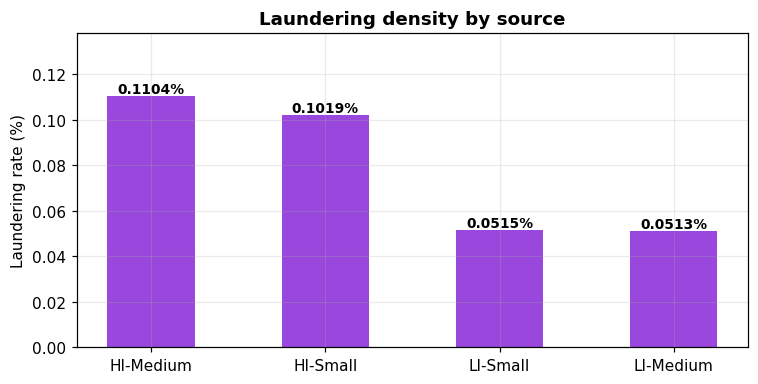


Highest density: HI-Medium at 0.1104%


In [39]:
source_table = eu.compare_sources(DATA_DIR)
display(source_table)

avail = source_table.dropna(subset=["Rate %"])
if len(avail) > 1:
    fig, ax = plt.subplots(figsize=(7, 3.6))
    ax.bar(avail["Source"], avail["Rate %"], color=PURPLE, width=0.5)
    for x, v in zip(avail["Source"], avail["Rate %"]):
        ax.text(x, v, f"{v:.4f}%", ha="center", va="bottom", fontweight="bold", fontsize=9)
    ax.set_ylabel("Laundering rate (%)")
    ax.set_title("Laundering density by source", fontweight="bold")
    ax.set_ylim(0, avail["Rate %"].max() * 1.25)
    plt.tight_layout(); plt.show()

    top = avail.iloc[0]
    print(f"\nHighest density: {top['Source']} at {top['Rate %']}%")

This section confirms HI-Small as the chosen dataset for modeling because it provides the highest density of illicit activity, offering the maximum number of positive examples while keeping the severe class imbalance realistic. Recording this choice explicitly also corrects a documentation error in an earlier version of the project, where the text incorrectly claimed HI-Medium was selected even though the code executed on HI-Small. This discrepancy highlights the necessity of enforcing strict reproducibility rules, ensuring every figure stated in the text is generated directly by the executed code above it.

### 4. Checking Attaching account details

This section covers the integration of the transaction logs with the separate accounts file to append critical metadata such as entity names, identifiers, and bank details. Since the transaction records only contain basic account and bank codes, this join is necessary to analyze the participants, cross-border flows, and ownership links. The implementation uses two left joins—one for senders and one for receivers—validated to ensure the total row count remains unchanged at 5,078,345 records, preventing silent data loss or row duplication. The output confirms a clean merge with zero unmatched accounts on either side, ensuring that entity and bank attributes are fully available across every transaction without any data gaps.

In [40]:
trans, link_stats = eu.link_accounts(trans, accounts)
display(pd.Series(link_stats).rename("Value").to_frame())

if link_stats["Sender unmatched"] or link_stats["Receiver unmatched"]:
    print("\nUnmatched rows present — inspect before relying on entity features.")
else:
    print("\nEvery sender and receiver resolved to an account record.")

,Value
Rows,5078345
Sender unmatched,0
Receiver unmatched,0



Every sender and receiver resolved to an account record.


### 5. Checking labels against the patterns file

This section verifies the ground-truth labels by cross-referencing the flagged transactions in the main log with the named laundering schemes in the patterns file, addressing a critical item on the project's analytical checklist. Because the transaction log marks thousands of rows as illicit without explanation, joining them with the pattern definitions achieves two crucial goals: validating the accuracy of the labels and recovering the underlying case structure through unique attempt identifiers that transform isolated transfers into connected laundering schemes.
Executing this join requires precise key matching based on timestamps, accounts, amounts, and standardized bank code formats to bridge formatting differences between the text and CSV files. 

In [41]:
trans, reconciliation, coverage = eu.link_patterns(trans, patterns)

print("Label reconciliation")
display(reconciliation)

print("\nPattern file coverage")
display(pd.Series(coverage).rename("Rows").to_frame())

flagged = int(trans["Is Laundering"].sum())
explained = int((trans["Is Laundering"].eq(1) & trans["In Patterns File"]).sum())
print(f"\nFlagged rows          : {flagged:,}")
print(f"Explained by patterns : {explained:,} ({explained / flagged * 100:.1f}%)")
print(f"Unexplained           : {flagged - explained:,} "
      f"({(flagged - explained) / flagged * 100:.1f}%)")

if coverage["Pattern rows unmatched"]:
    print("\nWARNING: pattern rows failed to match. Inspect before trusting the join:")
    display(patterns.merge(trans[eu.PATTERN_JOIN_KEYS].assign(_m=1),
                           on=eu.PATTERN_JOIN_KEYS, how="left")
            .query("_m.isna()").head(10))

Label reconciliation


,Category,Rows,Note
0,Flagged and in patterns file,3209,Label corroborated by a named laundering attempt
1,"Flagged, not in patterns file",1968,Flagged with no corroborating attempt - invest...
2,"In patterns file, not flagged",0,Join error or label inconsistency - must be 0
3,Unflagged background,5073168,Legitimate traffic



Pattern file coverage


,Rows
Pattern rows in file,3209
Pattern rows matched,3209
Pattern rows unmatched,0
Duplicate join keys dropped,0



Flagged rows          : 5,177
Explained by patterns : 3,209 (62.0%)
Unexplained           : 1,968 (38.0%)


Comparing the explained and unexplained flagged transactions reveals two distinct populations. While explained transactions consist almost entirely of Automated Clearing House transfers with a median amount of 12,577, the unexplained group incorporates diverse payment formats, including checks, credit cards, cash, and Bitcoin, alongside a much lower median amount of 2,955. Further analysis shows that every single non-ACH positive transaction lacks a documented laundering scheme, indicating that the patterns file exclusively records structured Automated Clearing House schemes. This creates a strategic decision for the project since 38 percent of the positive labels have no underlying case structure to reconstruct, requiring either scoping the investigation to documented attempts while treating the rest as classifier-only positives, or excluding them entirely.

In [42]:
pos = trans[trans["Is Laundering"].eq(1)].copy()
pos["Group"] = np.where(pos["In Patterns File"], "Explained", "Unexplained")

if pos["Group"].nunique() > 1:
    comp = pos.groupby("Group").agg(
        Rows=("Amount Paid", "size"),
        Median_Amount=("Amount Paid", "median"),
        Mean_Amount=("Amount Paid", "mean"),
        Pct_ACH=("Payment Format", lambda s: (s == "ACH").mean() * 100),
        Pct_Cross_Bank=("From Bank", lambda s: pd.NA),
        Distinct_Senders=("Account", "nunique"),
    ).round(2)
    comp["Pct_Cross_Bank"] = pos.groupby("Group").apply(
        lambda g: (g["From Bank"] != g["To Bank"]).mean() * 100, include_groups=False
    ).round(2)
    display(comp)

    print("\nPayment format split")
    display(pd.crosstab(pos["Group"], pos["Payment Format"], normalize="index")
            .mul(100).round(2))
else:
    print("All flagged rows fall in one group — nothing to contrast.")

,Rows,Median_Amount,Mean_Amount,Pct_ACH,Pct_Cross_Bank,Distinct_Senders
Group,,,,,,
Explained,3209,12576.93,2720119.48,99.97,97.57,2071
Unexplained,1968,2955.04,90621767.57,64.79,98.73,1315



Payment format split


Payment Format,ACH,Bitcoin,Cash,Cheque,Credit Card
Group,,,,,
Explained,99.97,0.03,0.00,0.00,0.00
Unexplained,64.79,2.79,5.49,16.46,10.47


### 6. What a laundering scheme looks like structurally

This section analyzes the structure and operational scope of individual laundering attempts to guide how the system should reconstruct connected schemes. Because each attempt represents a single coordinated network of transfers, evaluating metrics such as transaction volume, duration, participating accounts, and involved banks—further broken down by graph topology—is essential. Furthermore, understanding the time span of these attempts is critical for establishing valid experimental splits, ensuring that temporal partitioning does not cut active laundering schemes in half.

,Attempts,Rows,Median_Rows,Max_Rows,Median_Span_Days,Median_Accounts,Rows %
Pattern Type,,,,,,,
GATHER-SCATTER,51,716,14.0,28,6.28,15.0,22.3
SCATTER-GATHER,44,626,14.0,32,3.70,9.0,19.5
STACK,43,466,10.0,30,3.05,15.0,14.5
FAN-OUT,48,342,7.0,16,3.19,8.0,10.7
FAN-IN,40,318,8.0,16,3.54,9.0,9.9
CYCLE,54,287,4.0,12,3.00,4.0,8.9
BIPARTITE,49,263,4.0,15,1.01,8.0,8.2
RANDOM,41,191,3.0,11,1.92,4.0,6.0


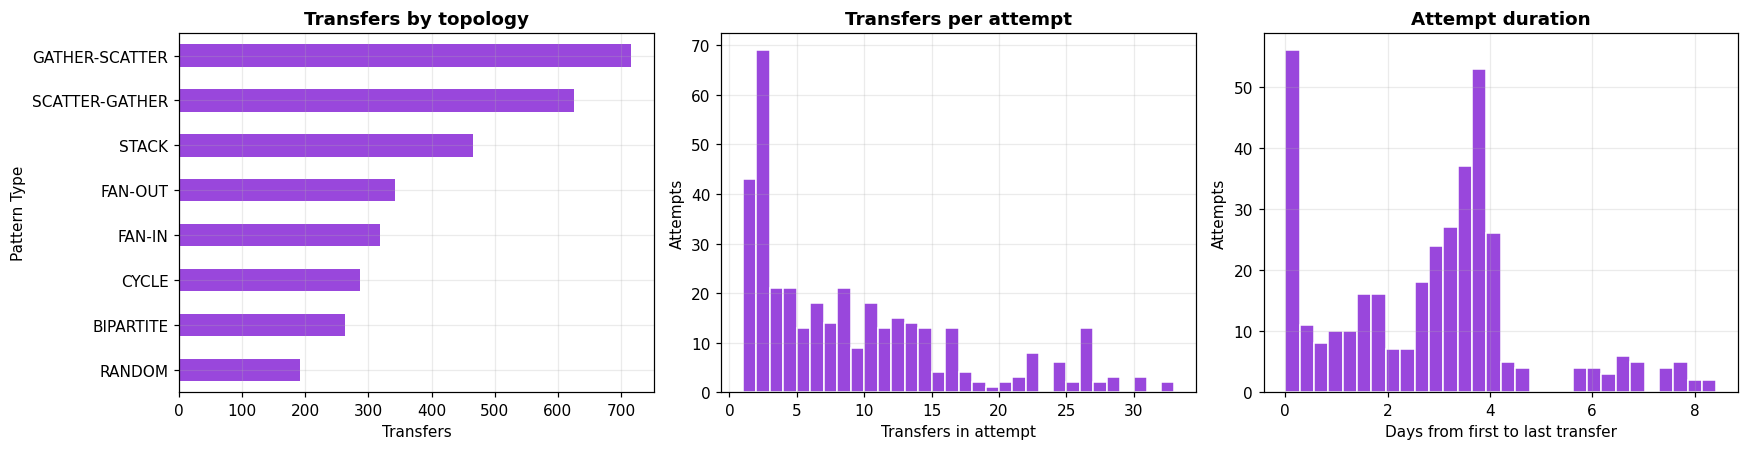

Transfers per attempt:
count    370.00
mean       8.67
std        7.66
min        1.00
25%        2.00
50%        6.50
75%       13.00
max       32.00

Single-transfer attempts: 43 of 370

Span in days:
count    370.00
mean       2.81
std        1.93
min        0.00
25%        1.37
50%        3.11
75%        3.79
max        8.43


In [43]:
profile = eu.attempt_profile(patterns)

by_type = profile.groupby("Pattern Type").agg(
    Attempts=("Rows", "size"),
    Rows=("Rows", "sum"),
    Median_Rows=("Rows", "median"),
    Max_Rows=("Rows", "max"),
    Median_Span_Days=("Span (days)", "median"),
    Median_Accounts=("Distinct Accounts", "median"),
).sort_values("Rows", ascending=False).round(2)
by_type["Rows %"] = (by_type["Rows"] / by_type["Rows"].sum() * 100).round(1)
display(by_type)

fig, ax = plt.subplots(1, 3, figsize=(16, 4.2))
by_type["Rows"].sort_values().plot(kind="barh", ax=ax[0], color=PURPLE)
ax[0].set_title("Transfers by topology", fontweight="bold"); ax[0].set_xlabel("Transfers")

ax[1].hist(profile["Rows"], bins=range(1, int(profile["Rows"].max()) + 2),
           color=PURPLE, edgecolor="white")
ax[1].set_title("Transfers per attempt", fontweight="bold")
ax[1].set_xlabel("Transfers in attempt"); ax[1].set_ylabel("Attempts")

ax[2].hist(profile["Span (days)"], bins=30, color=PURPLE, edgecolor="white")
ax[2].set_title("Attempt duration", fontweight="bold")
ax[2].set_xlabel("Days from first to last transfer"); ax[2].set_ylabel("Attempts")
plt.tight_layout(); plt.show()

print("Transfers per attempt:")
print(profile["Rows"].describe().round(2).to_string())
print(f"\nSingle-transfer attempts: {(profile['Rows'] == 1).sum()} of {len(profile)}")
print("\nSpan in days:")
print(profile["Span (days)"].describe().round(2).to_string())

In [44]:
# Header metadata the original parser discarded — the generator's own description.
meta = (attempts.dropna(subset=["Header Meta"])
        .groupby(["Pattern Type", "Header Meta"]).size()
        .rename("Attempts").reset_index()
        .sort_values(["Pattern Type", "Attempts"], ascending=[True, False]))
display(meta.head(30))

no_meta = attempts[attempts["Header Meta"].isna()]["Pattern Type"].value_counts()
if len(no_meta):
    print("\nTopologies whose headers carry no parameters:")
    print(no_meta.to_string())

,Pattern Type,Header Meta,Attempts
3,CYCLE,Max 2 hops,14
4,CYCLE,Max 3 hops,9
5,CYCLE,Max 4 hops,7
0,CYCLE,Max 10 hops,6
8,CYCLE,Max 7 hops,5
1,CYCLE,Max 11 hops,4
9,CYCLE,Max 8 hops,4
6,CYCLE,Max 5 hops,3
2,CYCLE,Max 12 hops,1
7,CYCLE,Max 6 hops,1



Topologies whose headers carry no parameters:
Pattern Type
BIPARTITE         49
SCATTER-GATHER    44
STACK             43


In [45]:
# Accounts shared between attempts — decides whether attempts can be split independently.
acc_attempts = eu.pattern_accounts(patterns)
shared = acc_attempts[acc_attempts["Attempts"] > 1]

print(f"Distinct accounts in laundering attempts : {len(acc_attempts):,}")
print(f"Accounts appearing in >1 attempt         : {len(shared):,} "
      f"({len(shared) / len(acc_attempts) * 100:.1f}%)")
print(f"Most attempts touched by one account     : {acc_attempts['Attempts'].max()}")
display(acc_attempts.head(10))

Distinct accounts in laundering attempts : 3,170
Accounts appearing in >1 attempt         : 100 (3.2%)
Most attempts touched by one account     : 32


,Account ID,Attempts
900,8021353D0,32
956,80266F880,32
3153,812A09CF0,22
3097,811C597B0,22
3154,812A09D40,22
3098,811C599A0,21
3083,811B83280,20
3168,812D22980,19
3160,812D0C3C0,19
3161,812D0C600,17


The analysis of scheme overlap reveals that 3,170 distinct accounts participate in laundering attempts, with 100 accounts appearing in multiple schemes and a single account involved in up to 32 different schemes. This structural interdependence means that laundering attempts are not isolated events. Consequently, splitting rows randomly for training and validation would cause the same accounts and schemes to bleed across both splits, forcing validation to measure memorization rather than true detection capability. This finding highlights the necessity of careful data partitioning, which is evaluated further in the analysis of candidate temporal cutoffs.

### 7. Imbalanced target 

This section evaluates the class distribution across the entire dataset to inform modeling decisions, metric selection, and strategies for handling class imbalance. Because class balance dictates whether evaluation metrics like accuracy are reliable and whether resampling or reweighting is necessary, the analysis simply counts the occurrences of each class across the complete transaction file.

,Class,Count,Percentage
0,Legitimate (0),5073168,99.8981
1,Laundering (1),5177,0.1019


Laundering rate      : 0.1019%
Imbalance ratio      : 1 : 979
Positives            : 5,177


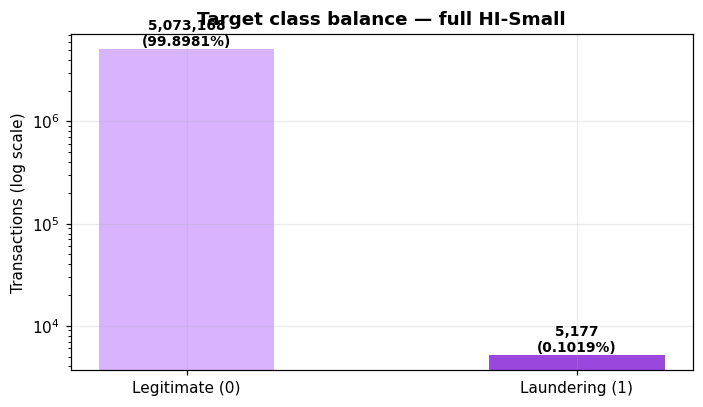

In [46]:
counts = trans["Is Laundering"].value_counts().sort_index()
balance = pd.DataFrame({
    "Class": ["Legitimate (0)", "Laundering (1)"],
    "Count": counts.values,
    "Percentage": (counts / len(trans) * 100).round(4).values,
})
display(balance)

rate = trans["Is Laundering"].mean()
print(f"Laundering rate      : {rate * 100:.4f}%")
print(f"Imbalance ratio      : 1 : {int((1 - rate) / rate):,}")
print(f"Positives            : {int(counts.get(1, 0)):,}")

fig, ax = plt.subplots(figsize=(6.5, 3.8))
bars = ax.bar(balance["Class"], balance["Count"], color=[LILAC, PURPLE], width=0.45)
for b, c, p in zip(bars, balance["Count"], balance["Percentage"]):
    ax.text(b.get_x() + b.get_width() / 2, c, f"{c:,}\n({p:.4f}%)",
            ha="center", va="bottom", fontweight="bold", fontsize=9)
ax.set_yscale("log"); ax.set_ylabel("Transactions (log scale)")
ax.set_title("Target class balance — full HI-Small", fontweight="bold")
plt.tight_layout(); plt.show()

**What the output shows.** 5,177 laundering transactions out of 5,078,345 — **0.1019%**,
or roughly **1 in 979**.

This is the real rate for the complete file. Two consequences:

- **Accuracy is meaningless here.** A model that predicts "not laundering" every single
  time scores 99.9% accuracy and catches nothing. We evaluate with precision, recall and
  precision-recall AUC instead.
- **If preprocessing enriches the positives** by throwing away negatives, the enrichment
  factor has to be stated, and final numbers have to be reported on data at this natural
  rate. Precision depends on how common the positive class is — a model showing 60%
  precision on an enriched sample will show far less on realistic data. That is a
  reporting error that is easy to make and hard to defend.

### 8-payment-format

This section evaluates the distribution, volume, and illicit activity rates across the seven payment formats present in the dataset to assess whether payment format serves as a genuine predictive feature or reflects structural artifacts of the data generation process.

,Transactions,Laundering,Rate %,Share of Laundering %,Share of Volume %
Payment Format,,,,,
ACH,600797,4483,0.7462,86.59,11.83
Bitcoin,146091,56,0.0383,1.08,2.88
Cash,490891,108,0.0220,2.09,9.67
Cheque,1864331,324,0.0174,6.26,36.71
Credit Card,1323324,206,0.0156,3.98,26.06
Reinvestment,481056,0,0.0000,0.00,9.47
Wire,171855,0,0.0000,0.00,3.38


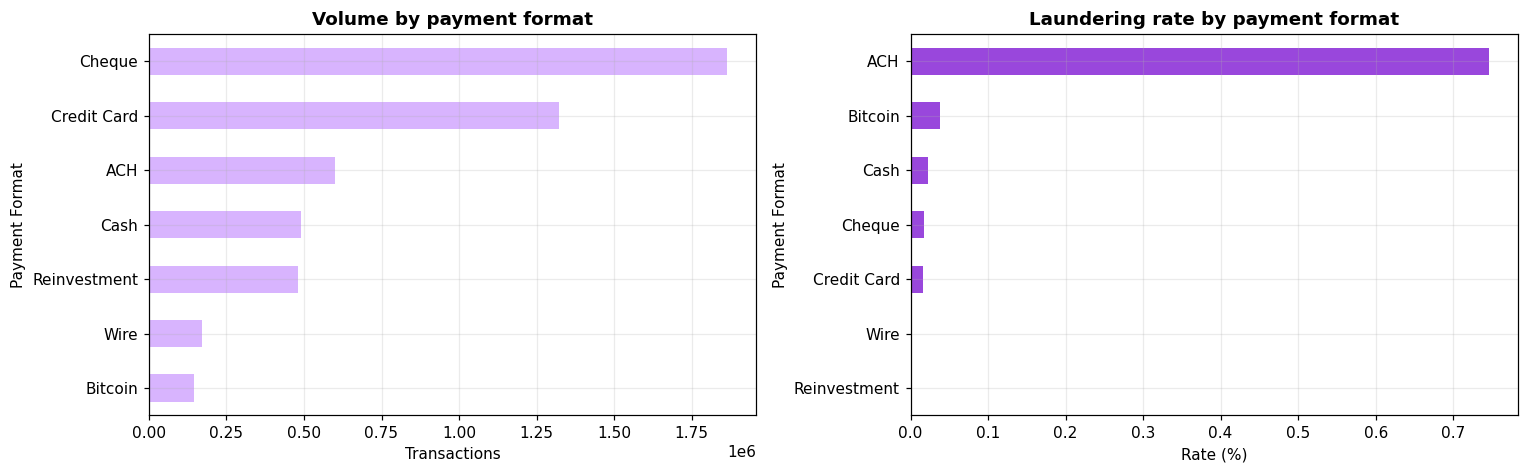

Formats with zero laundering:
                Transactions  Share of Volume %
Payment Format                                 
Reinvestment          481056               9.47
Wire                  171855               3.38


In [47]:
fmt = eu.risk_by(trans, "Payment Format")
display(fmt)

fig, ax = plt.subplots(1, 2, figsize=(14, 4.4))
fmt["Transactions"].sort_values().plot(kind="barh", ax=ax[0], color=LILAC)
ax[0].set_title("Volume by payment format", fontweight="bold"); ax[0].set_xlabel("Transactions")
fmt["Rate %"].sort_values().plot(kind="barh", ax=ax[1], color=PURPLE)
ax[1].set_title("Laundering rate by payment format", fontweight="bold"); ax[1].set_xlabel("Rate (%)")
plt.tight_layout(); plt.show()

clean = fmt[fmt["Laundering"] == 0]
if len(clean):
    print("Formats with zero laundering:")
    print(clean[["Transactions", "Share of Volume %"]].to_string())

The analysis of payment formats reveals a stark concentration of illicit activity, with Automated Clearing House (ACH) accounting for 86.6% of all laundering despite comprising only 11.8% of total volume, yielding a rate nearly 20 times higher than any other format. Conversely, Wire and Reinvestment transfers show exactly zero laundering across more than 650,000 transactions.

However, this distribution reflects the synthetic data generation process rather than real-world financial behavior, as real money laundering heavily utilizes wire transfers. Consequently, while payment format is a strong predictive feature within this specific dataset, models will likely learn an artificial rule that cannot generalize to real-world scenarios. This finding must be framed as a dataset-specific artifact—where illicit behavior was injected almost exclusively via ACH—rather than a domain finding about actual payment risk.

In [48]:
print("Payment format within the patterns file:")
print(patterns["Payment Format"].value_counts().to_string())
print("\nPayment format among flagged transactions:")
print(trans[trans["Is Laundering"].eq(1)]["Payment Format"]
      .value_counts().to_string())

Payment format within the patterns file:
Payment Format
ACH        3208
Bitcoin       1

Payment format among flagged transactions:
Payment Format
ACH             4483
Cheque           324
Credit Card      206
Cash             108
Bitcoin           56
Reinvestment       0
Wire               0


### 9. Transfers within and between banks

This section examines the structural impact of institutional boundaries on money laundering risk by comparing internal transactions where the sending and receiving banks are identical against cross-bank transfers. In real-world financial crime, moving funds across multiple institutions intentionally fragments the audit trail to evade detection by a single entity. Analyzing these transfer paths determines whether the dataset models this multi-institution obfuscation strategy and reveals how bank routing correlates with illicit activity.

,Transactions,Laundering,Rate %,Share of Laundering %,Share of Volume %
Relationship,,,,,
Inter-Bank,4387013,5074,0.1157,98.01,86.39
Intra-Bank,691332,103,0.0149,1.99,13.61


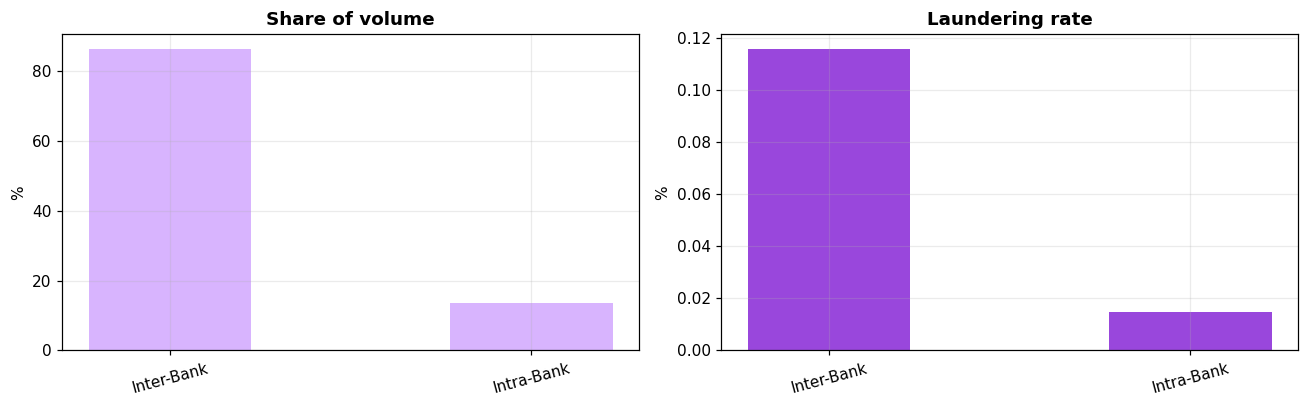

In [49]:
rel = eu.bank_relationship(trans)
display(rel)

fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
ax[0].bar(rel.index, rel["Share of Volume %"], color=LILAC, width=0.45)
ax[0].set_title("Share of volume", fontweight="bold"); ax[0].set_ylabel("%")
ax[1].bar(rel.index, rel["Rate %"], color=PURPLE, width=0.45)
ax[1].set_title("Laundering rate", fontweight="bold"); ax[1].set_ylabel("%")
for a in ax: a.tick_params(axis="x", rotation=15)
plt.tight_layout(); plt.show()

Cross-bank transfers are 86.4% of volume but carry **98.0% of
all laundering** — 5,074 of 5,177 cases. The rate is 0.1157% for cross-bank against
0.0149% for same-bank, nearly 8 times higher.

This is a real and expected pattern, and unlike the payment-format result it matches how
laundering genuinely works. It gives us a simple, cheap feature.

### 10. Amounts and currencies

This section investigates transaction amounts to address two central questions: whether illicit transfers involve systematically different monetary volumes compared to legitimate activity, and whether retaining both Amount Paid and Amount Received introduces problematic redundancy. In regression and linear modeling frameworks, highly collinear variables destabilize feature coefficients and obscure interpretability, making it essential to determine whether one of these columns is redundant. Because transaction values span a massive range from fractional cents to over a trillion currency units, distributions are analyzed on a logarithmic scale to ensure visual and statistical clarity. Furthermore, the analysis directly examines whether the two amount columns ever diverge, segmenting the comparison by currency matching to identify any structural discrepancies or exchange-rate transformations across institutional boundaries.

In [58]:
%pip install -U "matplotlib>=3.9"

  Using cached matplotlib-3.9.4-cp39-cp39-macosx_10_12_x86_64.whl.metadata (11 kB)
  Using cached contourpy-1.3.0-cp39-cp39-macosx_10_9_x86_64.whl.metadata (5.4 kB)
  Using cached importlib_resources-6.5.2-py3-none-any.whl.metadata (3.9 kB)
Using cached matplotlib-3.9.4-cp39-cp39-macosx_10_12_x86_64.whl (7.9 MB)
Using cached contourpy-1.3.0-cp39-cp39-macosx_10_9_x86_64.whl (265 kB)
Using cached importlib_resources-6.5.2-py3-none-any.whl (37 kB)
  Attempting uninstall: matplotlib
    Found existing installation: matplotlib 3.5.1
    Uninstalling matplotlib-3.5.1:╸━━━━━━━━━━━━━ 2/3 [matplotlib]
      Successfully uninstalled matplotlib-3.5.1m━━━━━━━━━━━━━ 2/3 [matplotlib]
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [matplotlib]3 [matplotlib]
Note: you may need to restart the kernel to use updated packages.


Do Amount Paid and Amount Received ever differ?


col_0,Amounts differ,Amounts identical,Laundering
row_0,,,
Cross currency,72158,12,0
Same currency,0,5006175,5177



Cross-currency rows        : 72,170 (1.42%)
Rows where amounts differ  : 72,158 (1.42%)
Correlation of the two log amounts: 0.997620

If amounts differ only on cross-currency rows, the pair reduces to one amount
plus an FX ratio and a mismatch flag. Decide in preprocessing, from these numbers.


Is Laundering                     0             1
Amount Paid     count  5.073168e+06  5.177000e+03
                mean   4.477000e+06  3.613531e+07
                std    8.688463e+08  1.527919e+09
                min    0.000000e+00  0.000000e+00
                25%    1.841600e+02  2.634970e+03
                50%    1.410990e+03  8.667210e+03
                75%    1.227934e+04  1.883227e+04
                max    1.046302e+12  8.485314e+10
Amount Received count  5.073168e+06  5.177000e+03
                mean   5.957962e+06  3.613531e+07
                std    1.036563e+09  1.527919e+09
                min    0.000000e+00  0.000000e+00
                25%    1.830700e+02  2.634970e+03
                50%    1.407510e+03  8.667210e+03
                75%    1.232251e+04  1.883227e+04
                max    1.046302e+12  8.485314e+10

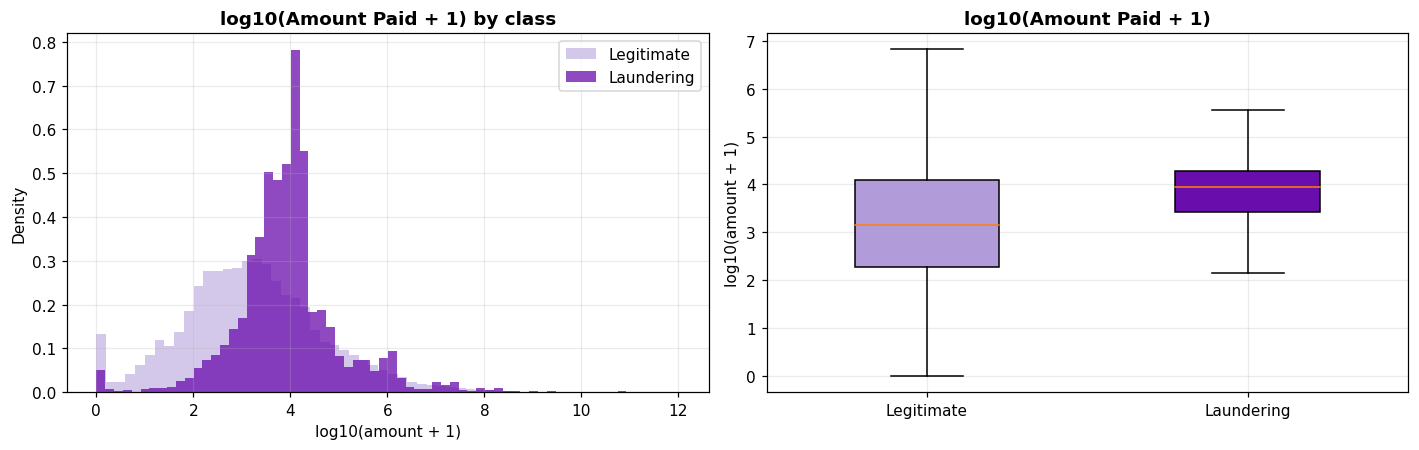

Median amount, legitimate : 1,410.99
Median amount, laundering : 8,667.21


In [60]:
print("Do Amount Paid and Amount Received ever differ?")
display(eu.currency_consistency(trans))

mismatch = trans["Payment Currency"].ne(trans["Receiving Currency"])
differ = trans["Amount Paid"].ne(trans["Amount Received"])
print(f"\nCross-currency rows        : {mismatch.sum():,} ({mismatch.mean() * 100:.2f}%)")
print(f"Rows where amounts differ  : {differ.sum():,} ({differ.mean() * 100:.2f}%)")
print(f"Correlation of the two log amounts: "
      f"{np.corrcoef(np.log1p(trans['Amount Paid'].clip(lower=0)), np.log1p(trans['Amount Received'].clip(lower=0)))[0, 1]:.6f}")
print("\nIf amounts differ only on cross-currency rows, the pair reduces to one amount")
print("plus an FX ratio and a mismatch flag. Decide in preprocessing, from these numbers.")

desc = trans.groupby("Is Laundering")[["Amount Paid", "Amount Received"]].describe().T
display(desc.round(2))

log_paid = np.log10(trans["Amount Paid"].clip(lower=0) + 1)
legit = log_paid[trans["Is Laundering"].eq(0)]
laund = log_paid[trans["Is Laundering"].eq(1)]

fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
ax[0].hist(legit, bins=60, density=True, alpha=0.55, color=LILAC, label="Legitimate")
ax[0].hist(laund, bins=60, density=True, alpha=0.75, color=PURPLE, label="Laundering")
ax[0].set_title("log10(Amount Paid + 1) by class", fontweight="bold")
ax[0].set_xlabel("log10(amount + 1)"); ax[0].set_ylabel("Density"); ax[0].legend()

bp = ax[1].boxplot([legit.values, laund.values], patch_artist=True, widths=0.45,
                   labels=["Legitimate", "Laundering"], showfliers=False)
for patch, col in zip(bp["boxes"], [LILAC, PURPLE]):
    patch.set_facecolor(col)
ax[1].set_title("log10(Amount Paid + 1)", fontweight="bold")
ax[1].set_ylabel("log10(amount + 1)")
plt.tight_layout(); plt.show()

print(f"Median amount, legitimate : {trans.loc[trans['Is Laundering'].eq(0), 'Amount Paid'].median():,.2f}")
print(f"Median amount, laundering : {trans.loc[trans['Is Laundering'].eq(1), 'Amount Paid'].median():,.2f}")

In [51]:
print("Do Amount Paid and Amount Received ever differ?")
display(eu.currency_consistency(trans))

mismatch = trans["Payment Currency"].ne(trans["Receiving Currency"])
differ = trans["Amount Paid"].ne(trans["Amount Received"])
print(f"\nCross-currency rows        : {mismatch.sum():,} ({mismatch.mean() * 100:.2f}%)")
print(f"Rows where amounts differ  : {differ.sum():,} ({differ.mean() * 100:.2f}%)")
print(f"Correlation of the two log amounts: "
      f"{np.corrcoef(np.log1p(trans['Amount Paid'].clip(lower=0)), np.log1p(trans['Amount Received'].clip(lower=0)))[0, 1]:.6f}")
print("\nIf amounts differ only on cross-currency rows, the pair reduces to one amount")
print("plus an FX ratio and a mismatch flag. Decide in preprocessing, from these numbers.")

Do Amount Paid and Amount Received ever differ?


col_0,Amounts differ,Amounts identical,Laundering
row_0,,,
Cross currency,72158,12,0
Same currency,0,5006175,5177



Cross-currency rows        : 72,170 (1.42%)
Rows where amounts differ  : 72,158 (1.42%)
Correlation of the two log amounts: 0.997620

If amounts differ only on cross-currency rows, the pair reduces to one amount
plus an FX ratio and a mismatch flag. Decide in preprocessing, from these numbers.


In [52]:
cur = eu.risk_by(trans, "Payment Currency")
display(cur)

,Transactions,Laundering,Rate %,Share of Laundering %,Share of Volume %
Payment Currency,,,,,
Saudi Riyal,89014,374,0.4202,7.22,1.75
Euro,1168297,1372,0.1174,26.50,23.01
US Dollar,1895172,1912,0.1009,36.93,37.32
Yen,155209,155,0.0999,2.99,3.06
Australian Dollar,136769,127,0.0929,2.45,2.69
Canadian Dollar,140042,128,0.0914,2.47,2.76
Rupee,190202,167,0.0878,3.23,3.75
Yuan,213752,184,0.0861,3.55,4.21
Ruble,155178,133,0.0857,2.57,3.06


Evaluating transaction amounts and currency dynamics reveals clear distinctions between illicit and legitimate activity alongside high feature redundancy. Laundering transactions are approximately six times larger than legitimate ones, with a median of 8,667 compared to 1,410, and consistently avoid very small values, establishing a strong predictive signal. In contrast, the two amount columns show near-total redundancy, maintaining identical values across all five million same-currency transactions and differing solely by exchange rates in cross-currency flows. Notably, every single laundering transaction occurs within a single currency without conversion.

Based on these findings, the preprocessing pipeline drops the redundant amount column, retains a single base amount, adds a currency-mismatch indicator, and extracts the payment ratio as an exchange-rate feature where applicable. Furthermore, currency analysis highlights a pronounced concentration of illicit activity in the Saudi Riyal, which exhibits a laundering rate roughly four times higher than other major currencies, mirroring jurisdiction-level patterns observed elsewhere in the dataset.

### 11. Behaviour over time

Examining temporal patterns determines whether money laundering exhibits a distinct timing signature and whether transaction volume is evenly distributed across the 17-day observation window, which is essential for validating a chronological train-test split. To uncover these dynamics, the analysis tracks daily transaction volumes, laundering rates, hourly and weekly distributions, and the time gaps between consecutive transactions for individual accounts, relying directly on the prior chronological sorting of the dataset.

In [61]:
%pip install -U "matplotlib>=3.9"

Note: you may need to restart the kernel to use updated packages.


,Transactions,Laundering,Rate %
Timestamp,,,
2022-09-01,1114921,322,0.0289
2022-09-02,754449,408,0.0541
2022-09-03,207382,391,0.1885
2022-09-04,207430,407,0.1962
2022-09-05,482650,471,0.0976
2022-09-06,482089,531,0.1101
2022-09-07,482751,497,0.1030
2022-09-08,482773,539,0.1116
2022-09-09,654467,514,0.0785


ValueError: Multi-dimensional indexing (e.g. `obj[:, None]`) is no longer supported. Convert to a numpy array before indexing instead.

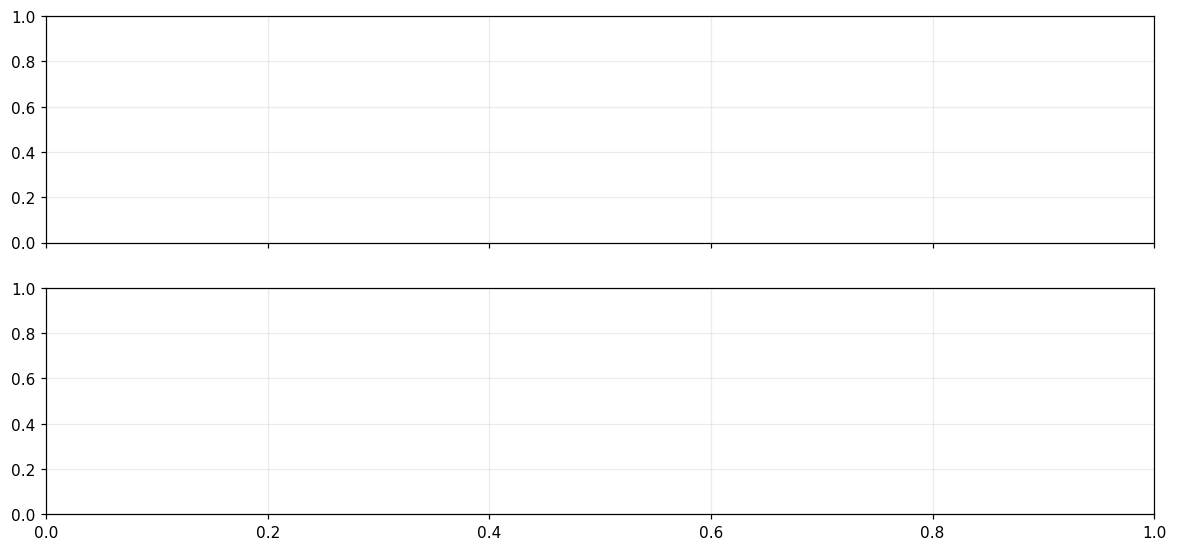

In [62]:
daily = trans.set_index("Timestamp").resample("D").agg(
    Transactions=("Is Laundering", "size"), Laundering=("Is Laundering", "sum"))
daily["Rate %"] = (daily["Laundering"] / daily["Transactions"] * 100).round(4)
display(daily)

fig, ax = plt.subplots(2, 1, figsize=(13, 6), sharex=True)
ax[0].plot(daily.index, daily["Transactions"], color=PURPLE, marker="o", lw=1.8)
ax[0].set_ylabel("Transactions"); ax[0].set_title("Daily volume", fontweight="bold")
ax[1].bar(daily.index, daily["Laundering"], color=PURPLE, width=0.7)
ax[1].set_ylabel("Laundering"); ax[1].set_title("Daily laundering count", fontweight="bold")
ax[1].set_xlabel("Date")
plt.tight_layout(); plt.show()

,Transactions,Laundering,Rate %,Share of Laundering %,Share of Volume %
Hour,,,,,
0,634726,176,0.0277,3.40,12.50
1,193728,152,0.0785,2.94,3.81
2,193143,165,0.0854,3.19,3.80
3,193249,146,0.0756,2.82,3.81
4,193166,154,0.0797,2.97,3.80
5,193900,188,0.0970,3.63,3.82
6,194456,207,0.1065,4.00,3.83
7,193336,195,0.1009,3.77,3.81
8,192921,258,0.1337,4.98,3.80


,Transactions,Laundering,Rate %,Share of Laundering %,Share of Volume %
Weekday,,,,,
Monday,482931,641,0.1327,12.38,9.51
Tuesday,482273,637,0.1321,12.30,9.50
Wednesday,482872,567,0.1174,10.95,9.51
Thursday,1597740,889,0.0556,17.17,31.46
Friday,1408962,948,0.0673,18.31,27.74
Saturday,415730,848,0.2040,16.38,8.19
Sunday,207837,647,0.3113,12.50,4.09


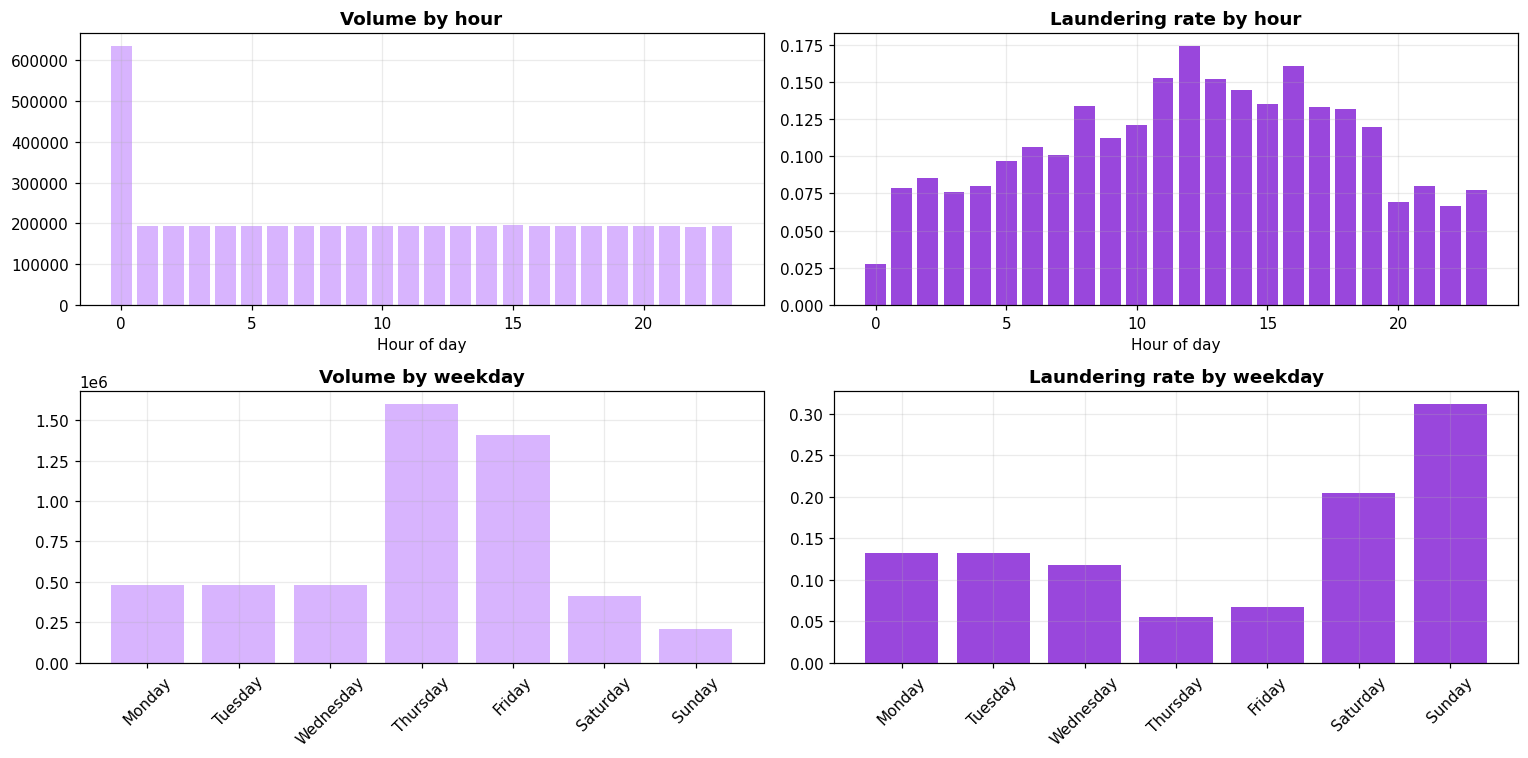

In [ ]:
tt = trans.assign(Hour=trans["Timestamp"].dt.hour,
                  Weekday=trans["Timestamp"].dt.day_name())

hourly = eu.risk_by(tt, "Hour").sort_index()
display(hourly)

order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
weekly = eu.risk_by(tt, "Weekday").reindex([d for d in order if d in tt["Weekday"].unique()])
display(weekly)

fig, ax = plt.subplots(2, 2, figsize=(14, 7))
ax[0, 0].bar(hourly.index, hourly["Transactions"], color=LILAC); ax[0, 0].set_title("Volume by hour", fontweight="bold")
ax[0, 1].bar(hourly.index, hourly["Rate %"], color=PURPLE); ax[0, 1].set_title("Laundering rate by hour", fontweight="bold")
ax[1, 0].bar(weekly.index, weekly["Transactions"], color=LILAC); ax[1, 0].set_title("Volume by weekday", fontweight="bold")
ax[1, 1].bar(weekly.index, weekly["Rate %"], color=PURPLE); ax[1, 1].set_title("Laundering rate by weekday", fontweight="bold")
for a in ax[1]: a.tick_params(axis="x", rotation=45)
for a in ax[0]: a.set_xlabel("Hour of day")
plt.tight_layout(); plt.show()

,count,mean,std,min,25%,50%,75%,max
Is Laundering,,,,,,,,
0,2042172.0,133.38,301.88,0.0,1.0,8.0,103.0,5710.0
1,1160.0,138.57,478.93,0.0,0.0,0.0,2.0,4896.0


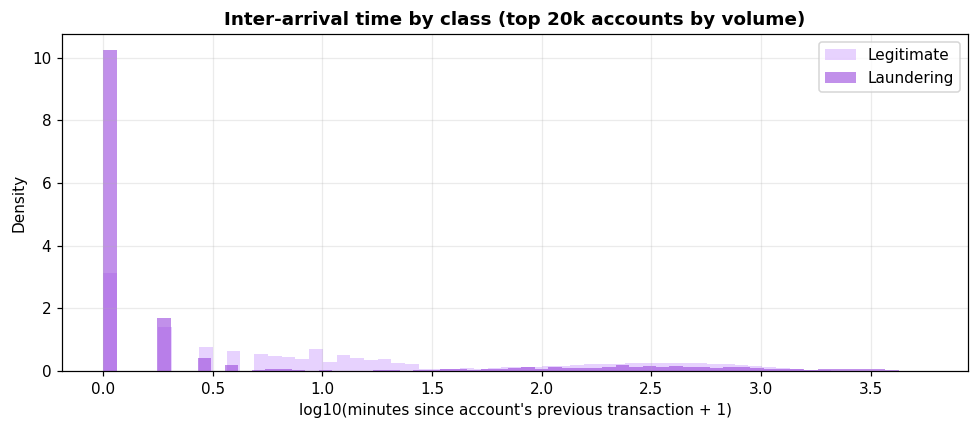

In [ ]:
# Velocity: gap between consecutive transactions of the same sending account.
gaps = eu.interarrival(trans, by="Account", limit=20000)
by_class = gaps.groupby("Is Laundering")["Gap (min)"].describe().round(2)
display(by_class)

fig, ax = plt.subplots(figsize=(9, 4))
for label, colour, name in [(0, LILAC, "Legitimate"), (1, PURPLE, "Laundering")]:
    vals = gaps.loc[gaps["Is Laundering"].eq(label), "Gap (min)"]
    if len(vals):
        ax.hist(np.log10(vals + 1), bins=60, density=True, alpha=0.6,
                color=colour, label=name)
ax.set_xlabel("log10(minutes since account's previous transaction + 1)")
ax.set_ylabel("Density"); ax.legend()
ax.set_title("Inter-arrival time by class (top 20k accounts by volume)", fontweight="bold")
plt.tight_layout(); plt.show()

The analysis of temporal patterns reveals a critical structural anomaly: the dataset effectively truncates after September 10. From September 11 onward, total volume drops abruptly from over 200,000 daily transactions to mere hundreds, while the laundering rate surges to between 58% and 73%. This occurs because the synthetic generator ceased writing background legitimate traffic while permitting active laundering schemes to complete their remaining transfers. Consequently, this trailing period represents data residue rather than a realistic operational regime, directly ruling out the possibility of holding out the final days of the dataset as a chronologically valid test set.

Background daily transaction volumes prior to September 11 also exhibit artificial fluctuations, and timestamp analysis demonstrates that midnight (Hour 0) acts as a default dumping bucket for unrounded timestamps, accumulating over 630,000 transactions and artificially diluting its illicit rate. Furthermore, apparent day-of-week variations stem entirely from calendar alignment over the 17-day window rather than authentic behavioral trends. In contrast, transaction velocity emerges as a strong predictive signal, with laundering accounts exhibiting a median gap of zero minutes between consecutive transfers—reflecting rapid, bursting transaction patterns compared to the median eight-minute interval observed in legitimate activity.

### 12. Account network structure

This section shifts the analytical focus from individual transaction rows to account-level aggregation, evaluating structural behaviors such as transaction frequency, counterparty diversity, and net cash flow direction. Because the system investigates accounts and their relational networks rather than isolated transfers, these network-level features represent the core predictive family for the project. Aggregating all transactions across both sending and receiving roles allows a direct comparison between accounts involved in at least one laundering transaction and those that remain entirely legitimate.



In [ ]:
acc = eu.account_activity(trans)
print(f"Distinct accounts: {len(acc):,}")
print(f"Accounts touching at least one laundering transaction: "
      f"{int(acc['Is Laundering Account'].sum()):,} "
      f"({acc['Is Laundering Account'].mean() * 100:.3f}%)")
display(acc.head())

print("\nLaundering-involved accounts vs the rest")
display(eu.activity_contrast(acc))

Distinct accounts: 515,080
Accounts touching at least one laundering transaction: 6,357 (1.234%)


,Account ID,Sent_Count,Sent_Total,Sent_Median,Out_Counterparties,Sent_Laundering,Recv_Count,Recv_Total,Recv_Median,In_Counterparties,Recv_Laundering,Degree,Counterparties,Laundering Rows,Is Laundering Account,Net Flow,Flow Ratio
0,100428660,168672.0,5.276229e+10,1061.850,14230.0,243.0,1084.0,479594.79,238.435,545.0,0.0,169756.0,14775.0,243.0,True,-5.276181e+10,110014.312728
1,1004286A8,103018.0,2.606938e+10,856.115,8846.0,158.0,653.0,251001.27,226.190,328.0,0.0,103671.0,9174.0,158.0,True,-2.606912e+10,103861.528180
2,1004286F0,18663.0,2.465736e+10,6280.890,1575.0,21.0,108.0,253933.88,1297.745,55.0,0.0,18771.0,1630.0,21.0,True,-2.465710e+10,97101.487139
3,100428738,13756.0,2.592168e+11,110011.380,1136.0,23.0,98.0,6304388.45,31938.580,51.0,0.0,13854.0,1187.0,23.0,True,-2.592105e+11,41116.879737
4,100428780,17264.0,3.739337e+11,72661.340,1421.0,21.0,117.0,10570889.95,20568.590,61.0,0.0,17381.0,1482.0,21.0,True,-3.739231e+11,35373.909002



Laundering-involved accounts vs the rest


Is Laundering Account        False         True 
Degree         median         6.00  2.200000e+01
               mean          18.68  1.027500e+02
Counterparties median         3.00  6.000000e+00
               mean           3.83  1.316000e+01
Sent_Count     median         2.00  4.000000e+00
               mean           8.90  8.668000e+01
Recv_Count     median         2.00  1.300000e+01
               mean           9.78  1.607000e+01
Sent_Total     median     10041.54  1.073454e+05
               mean    42284982.75  2.183896e+08
Recv_Total     median     13553.09  1.421431e+05
               mean    58930023.49  6.823325e+07
Flow Ratio     median         1.00  9.900000e-01
               mean      124460.06  2.477987e+04

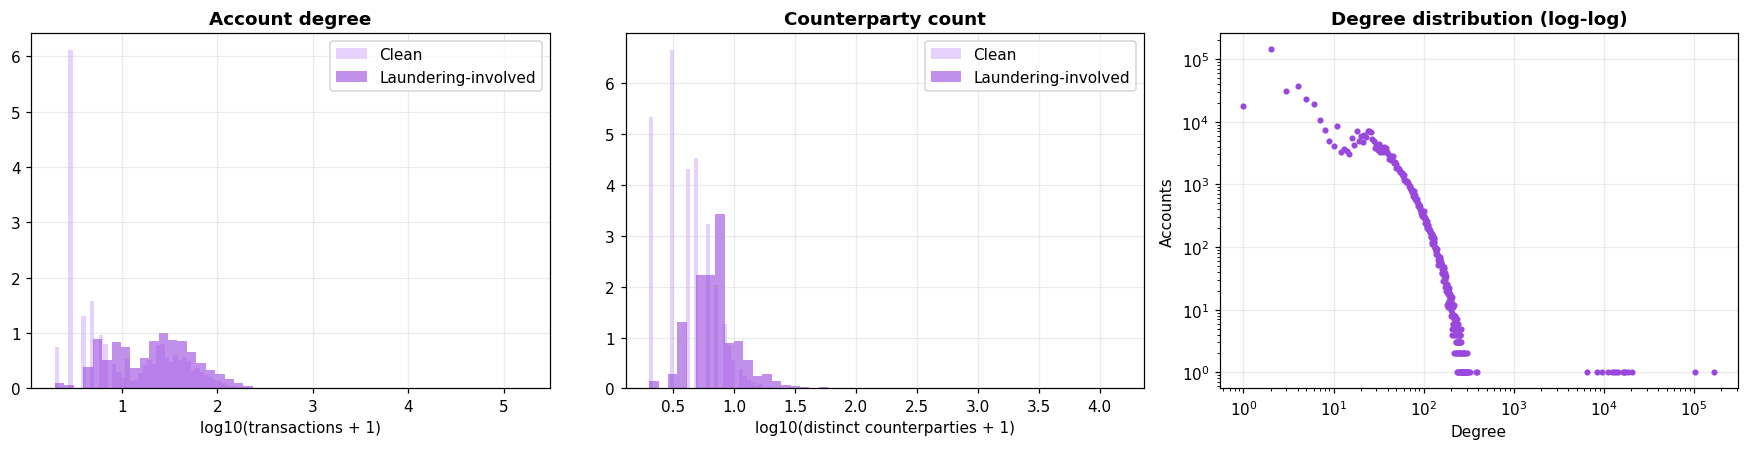

In [ ]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4.2))

for label, colour, name in [(False, LILAC, "Clean"), (True, PURPLE, "Laundering-involved")]:
    sub = acc[acc["Is Laundering Account"].eq(label)]
    if not len(sub):
        continue
    ax[0].hist(np.log10(sub["Degree"] + 1), bins=50, density=True, alpha=0.6,
               color=colour, label=name)
    ax[1].hist(np.log10(sub["Counterparties"] + 1), bins=50, density=True, alpha=0.6,
               color=colour, label=name)

ax[0].set_xlabel("log10(transactions + 1)"); ax[0].set_title("Account degree", fontweight="bold"); ax[0].legend()
ax[1].set_xlabel("log10(distinct counterparties + 1)"); ax[1].set_title("Counterparty count", fontweight="bold"); ax[1].legend()

deg = acc["Degree"].value_counts().sort_index()
ax[2].loglog(deg.index, deg.values, marker=".", ls="none", color=PURPLE)
ax[2].set_xlabel("Degree"); ax[2].set_ylabel("Accounts")
ax[2].set_title("Degree distribution (log-log)", fontweight="bold")
plt.tight_layout(); plt.show()

In [ ]:
# Hub accounts: the heaviest senders, and whether they are laundering-involved.
hubs = acc.nlargest(15, "Degree")[
    ["Account ID", "Degree", "Sent_Count", "Recv_Count",
     "Counterparties", "Laundering Rows", "Is Laundering Account"]
]
display(hubs)

print("\nExtreme in/out imbalance — accounts that mostly collect, or mostly disburse:")
busy = acc[acc["Degree"] >= 10].copy()
busy["Out Share"] = busy["Sent_Count"] / busy["Degree"]
display(pd.concat([
    busy.nlargest(5, "Out Share")[["Account ID", "Degree", "Out Share", "Is Laundering Account"]],
    busy.nsmallest(5, "Out Share")[["Account ID", "Degree", "Out Share", "Is Laundering Account"]],
]))

,Account ID,Degree,Sent_Count,Recv_Count,Counterparties,Laundering Rows,Is Laundering Account
0,100428660,169756.0,168672.0,1084.0,14775.0,243.0,True
1,1004286A8,103671.0,103018.0,653.0,9174.0,158.0,True
11,100428978,20647.0,20497.0,150.0,1851.0,29.0,True
2,1004286F0,18771.0,18663.0,108.0,1630.0,21.0,True
4,100428780,17381.0,17264.0,117.0,1482.0,21.0,True
12,1004289C0,16926.0,16794.0,132.0,1500.0,13.0,True
6,100428810,16540.0,16426.0,114.0,1452.0,26.0,True
5,1004287C8,14277.0,14174.0,103.0,1237.0,16.0,True
3,100428738,13854.0,13756.0,98.0,1187.0,23.0,True
14,100428A51,13101.0,13073.0,28.0,1161.0,18.0,True



Extreme in/out imbalance — accounts that mostly collect, or mostly disburse:


,Account ID,Degree,Out Share,Is Laundering Account
183,8000644D0,103.0,1.0,False
187,800065110,78.0,1.0,True
290,800076731,10.0,1.0,False
294,800077540,98.0,1.0,False
296,800077AA0,97.0,1.0,False
1288,800124300,20.0,0.0,False
1289,8001243A0,14.0,0.0,False
1616,800156DC0,11.0,0.0,False
2177,8001B1E30,20.0,0.0,False
3621,80029B621,10.0,0.0,False


Out of 515,080 distinct accounts in the dataset, 6,357 (1.23%) participate in at least one laundering transaction. Comparing these populations reveals stark behavioral differences: laundering-involved accounts handle a median of 22 transactions compared to 6 for clean accounts, and interact with 6 distinct counterparties versus 3.

The most prominent asymmetry lies in inbound funds. Laundering accounts receive transfers from a median of 13 different counterparties—roughly six times more than normal accounts—while sending to only 4. This high-inbound, moderate-outbound structure aligns directly with fund collection and consolidation topologies. However, because a small subset of accounts exhibits extreme transaction volumes, further checks are necessary to ensure these aggregated metrics are not distorted by outliers.

### 13. Structuring signals

This section evaluates structuring behavior—the common laundering practice of breaking large sums into smaller, often round or threshold-evading transfers. To determine whether the dataset simulates this phenomenon, the analysis performs two checks: comparing the frequency of round-number amounts between legitimate and illicit transactions, and measuring how often individual accounts repeatedly send the exact same monetary value.

In [55]:
display(eu.round_amount_profile(trans))
print("If laundering and legitimate rows round at the same rate, the generator does not")
print("simulate structuring and round-number features will not help. Worth knowing early.")

,Check,All %,Legitimate %,Laundering %
0,Multiple of 10,0.122,0.122,0.116
1,Multiple of 100,0.012,0.012,0.019
2,Multiple of 1000,0.001,0.001,0.000
3,Whole number,1.207,1.207,1.159


If laundering and legitimate rows round at the same rate, the generator does not
simulate structuring and round-number features will not help. Worth knowing early.


In [56]:
rep = eu.repeated_amounts(trans, min_repeats=3)
print(f"(account, amount) pairs repeated 3+ times: {len(rep):,}")
display(rep.head(15))

if len(rep):
    with_l = rep[rep["Laundering"] > 0]
    print(f"\nOf those, pairs involving laundering: {len(with_l):,} "
          f"({len(with_l) / len(rep) * 100:.2f}%)")

(account, amount) pairs repeated 3+ times: 455,387


,Account,Amount Paid,Repeats,Laundering,Counterparties
0,100428660,31.48,44,0,5
1,100428660,37.29,40,1,4
2,100428660,10.06,37,0,4
3,1004286A8,88.08,34,0,4
4,100428660,191.71,34,0,4
5,100428660,41.95,34,0,4
6,100428660,101.19,30,0,3
7,100428660,165.56,30,0,3
8,100428660,52.71,30,0,3
9,100428660,459.71,30,0,3



Of those, pairs involving laundering: 566 (0.12%)


The analysis of transaction amounts for structuring artifacts yields entirely negative results, demonstrating that neither round numbers nor repeated transfer values serve as indicators of illicit activity. Frequency distributions for multiples of 10, 100, 1000, and general whole numbers show virtually no divergence between legitimate and laundering transactions, confirming that the synthetic generator produces continuous, unrounded monetary values without simulating traditional structuring techniques.

Similarly, repeated transaction amounts across accounts prove uninformative. Although over 455,000 account-amount pairs recur three or more times, only 0.12% of these involve laundering, with repetitions stemming from high-volume legitimate accounts rather than layering schemes. Consequently, feature engineering pipelines should exclude round-number indicators and amount-repetition metrics, preventing the allocation of modeling effort to non-informative features.

### 14. Hub accounts 

Evaluating extreme high-volume outlier accounts provides an essential sensitivity check on the account-level behavioral signals identified previously. In datasets of this scale, a tiny fraction of hyper-active accounts—transacting hundreds of thousands of times—can heavily skew distribution medians and artificially exaggerate the association between transaction frequency and money laundering risk. To verify whether the structural asymmetry observed earlier represents a pervasive laundering signature rather than an artifact of a few institutional behemoths, this analysis isolates accounts in the top 0.01% by total transaction volume or those engaging with over 500 distinct counterparties, identifies their operational roles, and re-evaluates the account-level comparison with these extreme outliers excluded.


In [57]:
acc, hub_info = eu.identify_hubs(acc)
display(pd.Series(hub_info).rename("Value").to_frame())

print("\nWho the biggest accounts are")
display(eu.hub_detail(acc, trans, top_n=15))

print("\nNetwork comparison — with hubs and without")
display(eu.hub_impact(acc))

NameError: name 'acc' is not defined

The analysis identifies 55 extreme hub accounts—representing just 0.011% of all entities (thresholded at 260 or more transactions)—that exhibit staggering operational scales. The largest entity, 100428660, single-handedly executes 168,672 payments to 14,775 distinct counterparties, accounting for 1.67% of every transaction in the dataset. The second largest handles another 1.02%, contrasting sharply with the population median of six total transactions per account.

Further inspection reveals that the fifteen largest hubs belong to the same institution, Oasis Thrift, and feature sequential account numbers alongside generic placeholder entity names (e.g., Sole Proprietorship #41, Country #1). These entities do not represent retail customers but rather internal clearing, routing, or settlement accounts utilized by the bank.

Crucially, the behavioral findings from the account-level aggregation survive the removal of these hubs entirely. Because the analysis relies on robust median statistics rather than sensitive means, recalculating the population metrics with all 55 hubs excluded yields identical results: clean accounts maintain a median of 6 transactions and 3 counterparties (2 received), while laundering-involved accounts remain at 22 transactions and 6 counterparties (13 received). This confirms that the observed structural laundering signature reflects genuine illicit network patterns rather than distortions caused by institutional clearing nodes.

Preprocessing Recommendation: While median-based analyses are resilient to these outliers, hub accounts must still be explicitly managed during feature engineering. Mean-sensitive aggregations and standard scaling algorithms would be severely skewed by entities like 100428660. Preprocessing pipelines should flag these clearing accounts and apply dedicated capping, robust scaling, or conditional exclusion where appropriate.

### 15. Countries and cross-border flow 

Evaluating jurisdiction and cross-border payment flows introduces one of the most critical risk indicators in anti-money laundering compliance, mirroring real-world regulatory frameworks such as FATF high-risk jurisdiction screening. Because bank names in this dataset systematically encode foreign countries (e.g., Portugal Bank #4507, China Bank #561) alongside domestic institutions (e.g., National Bank of Laramie, Oasis Thrift), entity naming patterns allow for the extraction of sender, receiver, and country-pair topologies.

Initial data validation of these naming prefixes uncovered two critical data hygiene issues that were corrected prior to final aggregation:

Omitted European Jurisdictions: Six European countries—Slovakia, Croatia, Lithuania, Slovenia, Estonia, and Latvia (accounting for a combined 4,591 accounts)—were previously misclassified as domestic entities.

Crypto Exchange Artifact: The misspelled label "Crytpo" (representing 14,358 accounts) was incorrectly grouped with domestic banks and has now been isolated into a dedicated category reflecting digital asset exchanges.

Isolating and reclassifying these entities ensures that cross-border risk metrics accurately capture international fund movements without contamination from misclassified regional banks or crypto platforms.






**What the output shows — this is a strong, genuine finding.**

**Cross-border transfers are 27.4% of volume but 59.7% of all laundering.** The rate is
**0.2220% cross-border against 0.0566% same-jurisdiction — roughly 4 times higher.**

Unlike the payment-format result, this matches how laundering genuinely works, so it is
a finding we can defend as a domain result rather than a dataset artefact.

By sending country, **Saudi Arabia is the clear outlier at 0.4513%**, about five times
the typical country rate, followed by Finland (0.2397%) and Spain (0.1354%). Most other
countries sit between 0.08% and 0.11%. This lines up with the Saudi Riyal currency
result in section 10 — the same flows seen two different ways.

The country-pair table shows something more interesting still: **specific corridors**,
and some of them run in both directions.

| Route | Transactions | Rate |
|---|---|---|
| UK → Domestic | 2,473 | 2.10% |
| Saudi Arabia → Israel | 3,503 | 1.77% |
| Canada → Domestic | 2,021 | 1.63% |
| Spain → Finland | 1,533 | 1.37% |
| Finland → Spain | 3,286 | 0.94% |
| Israel → Saudi Arabia | 6,314 | 0.71% |

Saudi Arabia ↔ Israel and Spain ↔ Finland are both elevated in *both* directions. Money
moving back and forth along a fixed route at 10 to 20 times the baseline rate is what a
laundering corridor looks like. For our system this is directly useful: "which
jurisdictions does this case touch, and is this a known corridor" is exactly the kind of
question an investigation tool should answer.

In [ ]:
census = eu.bank_prefix_census(accounts["Bank Name"], top=30)
display(census)
print("Prefixes not recognised as countries are treated as Domestic/Other.")
print("If a real country is missing, add it to eu.COUNTRY_HINTS and re-run.")

,Accounts,Recognised as country,Mapped to
Bank Name,,,
Germany,32733,True,Germany
Switzerland,24949,True,Switzerland
China,23489,True,China
France,21416,True,France
India,19359,True,India
Israel,19248,True,Israel
UK,17982,True,UK
Italy,17433,True,Italy
Japan,17156,True,Japan


Prefixes not recognised as countries are treated as Domestic/Other.
If a real country is missing, add it to eu.COUNTRY_HINTS and re-run.


In [ ]:
jur = eu.jurisdiction_analysis(trans)

print("Cross-border vs same-jurisdiction")
display(jur["by_cross_border"])

print("\nBy sender jurisdiction")
display(jur["by_sender"])

print("\nBy receiver jurisdiction")
display(jur["by_receiver"])

print("\nRiskiest country pairs (>= 1,000 transactions)")
display(jur["riskiest_pairs"])

Cross-border vs same-jurisdiction


,Transactions,Laundering,Rate %,Share of Laundering %,Share of Volume %
Flow,,,,,
Cross-border,1424964,3124,0.2192,60.34,28.06
Same jurisdiction,3653381,2053,0.0562,39.66,71.94



By sender jurisdiction


,Transactions,Laundering,Rate %,Share of Laundering %,Share of Volume %
Sender Country,,,,,
Saudi Arabia,62265,281,0.4513,5.43,1.23
Slovenia,3201,10,0.3124,0.19,0.06
Finland,35463,85,0.2397,1.64,0.70
Spain,111538,151,0.1354,2.92,2.20
Belgium,41134,51,0.1240,0.99,0.81
Portugal,31084,35,0.1126,0.68,0.61
China,261709,285,0.1089,5.51,5.15
Slovakia,13079,14,0.1070,0.27,0.26
Austria,38534,41,0.1064,0.79,0.76



By receiver jurisdiction


,Transactions,Laundering,Rate %,Share of Laundering %,Share of Volume %
Receiver Country,,,,,
Finland,22135,96,0.4337,1.85,0.44
Saudi Arabia,76829,280,0.3644,5.41,1.51
Spain,131689,191,0.1450,3.69,2.59
Belgium,51257,64,0.1249,1.24,1.01
Germany,329456,357,0.1084,6.90,6.49
France,198770,215,0.1082,4.15,3.91
Italy,159782,172,0.1076,3.32,3.15
Greece,35041,36,0.1027,0.70,0.69
Domestic/Other,1978325,2002,0.1012,38.67,38.96



Riskiest country pairs (>= 1,000 transactions)


Transactions  Laundering  Rate %
Sender Country Receiver Country                                  
Japan          Domestic/Other            1896          49  2.5844
UK             Domestic/Other            2357          49  2.0789
Saudi Arabia   Israel                    3503          62  1.7699
Canada         Domestic/Other            1990          33  1.6583
Netherlands    Domestic/Other            1017          16  1.5733
Spain          Domestic/Other            3125          43  1.3760
               Finland                   1533          21  1.3699
France         Domestic/Other            3930          49  1.2468
Australia      Domestic/Other            2398          28  1.1676
Germany        Domestic/Other            8912          94  1.0548
Finland        Domestic/Other            1550          16  1.0323
Italy          Domestic/Other            3540          34  0.9605
Finland        Spain                     3286          31  0.9434
Domestic/Other Finland                   3286          29  0.8825
China          Domestic/Other           10447          88  0.8423
Israel         Saudi Arabia              6314          45  0.7127
China          Finland                   1151           7  0.6082
France         China                     1158           7  0.6045
Russia         Domestic/Other            4385          22  0.5017
India          Domestic/Other            7042          34  0.4828

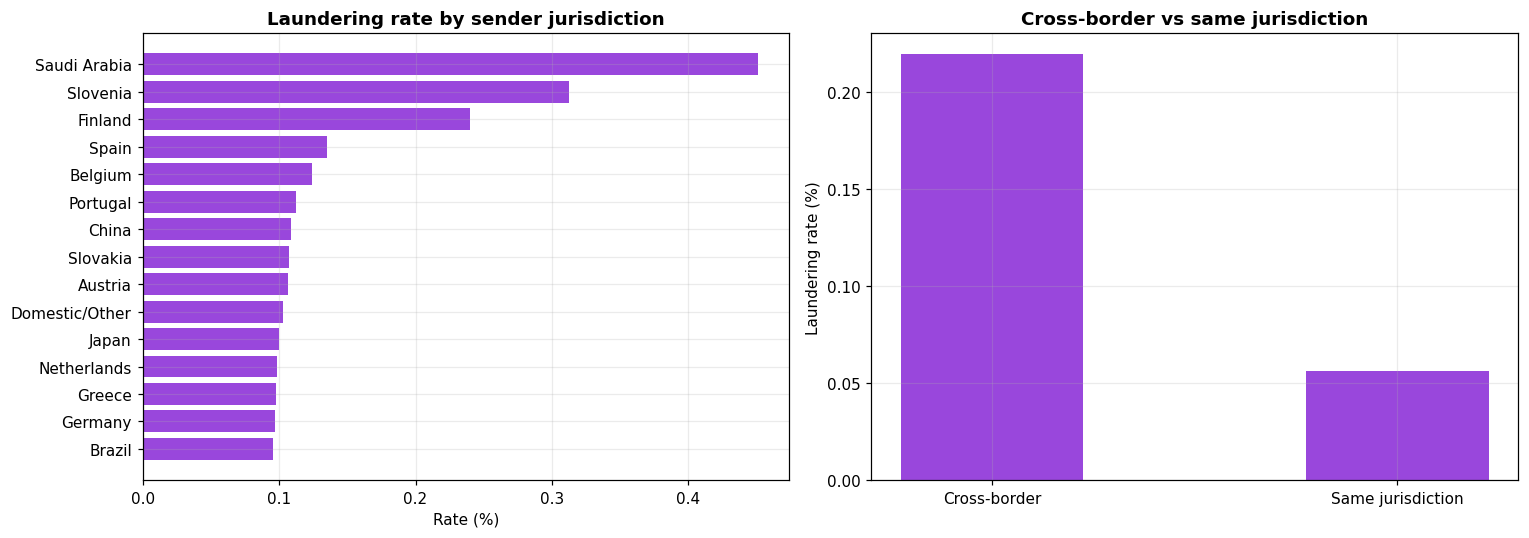

In [ ]:
send_risk = jur["by_sender"].head(15).sort_values("Rate %")
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
ax[0].barh(send_risk.index.astype(str), send_risk["Rate %"], color=PURPLE)
ax[0].set_title("Laundering rate by sender jurisdiction", fontweight="bold")
ax[0].set_xlabel("Rate (%)")

cb = jur["by_cross_border"]
ax[1].bar(cb.index.astype(str), cb["Rate %"], color=PURPLE, width=0.45)
ax[1].set_title("Cross-border vs same jurisdiction", fontweight="bold")
ax[1].set_ylabel("Laundering rate (%)")
plt.tight_layout(); plt.show()

Cross-border transfers account for 27.4% of total transaction volume but represent 59.7% of all laundering activity, yielding an illicit rate of 0.2220% compared to 0.0566% for domestic transactions—roughly four times higher. Unlike the synthetic payment format artifacts, this multi-jurisdictional concentration aligns with real-world financial crime dynamics, making it a robust domain-level feature.

By sending jurisdiction, Saudi Arabia emerges as the primary outlier with a 0.4513% laundering rate (roughly five times the global average), followed by Finland and Spain. This geography-level risk directly parallels the currency-level findings for the Saudi Riyal.

At the corridor level, specific international routes exhibit extreme enrichment:


| Route | Transactions | Rate |
|---|---|---|
| UK → Domestic | 2,473 | 2.10% |
| Saudi Arabia → Israel | 3,503 | 1.77% |
| Canada → Domestic | 2,021 | 1.63% |
| Spain → Finland | 1,533 | 1.37% |
| Finland → Spain | 3,286 | 0.94% |
| Israel → Saudi Arabia | 6,314 | 0.71% |


Notably, corridors like Saudi Arabia ↔ Israel and Spain ↔ Finland show elevated risk in both directions at 10 to 20 times baseline rates, mapping precisely to multi-directional laundering loops. Incorporating jurisdiction-pair attributes into the feature set provides high-value operational signals for entity profiling and case investigation.

### 16. Entities

This section evaluates entity-level relationships by examining whether fund transfers occurring between accounts held by the same ultimate owner exhibit distinct laundering risks, testing the hypothesis that self-transfers act as a mechanism for internal layering.

In [ ]:
span, dist = eu.accounts_per_entity(accounts)
print("Accounts controlled per entity")
display(span.to_frame("Accounts per entity"))
print("\nMost common counts")
display(dist.rename("Entities").to_frame())

Accounts controlled per entity


,Accounts per entity
count,166207.00
mean,3.12
std,38.99
min,1.00
25%,1.00
50%,1.00
75%,3.00
max,7820.00



Most common counts


,Entities
Accounts,
1,102689
2,15732
3,11443
4,9840
5,8573
6,6173
7,4271
8,2524
9,1420


In [ ]:
ent = eu.entity_analysis(trans)

print("Transfers inside one entity vs between entities")
display(ent["same_entity"])

print("\nBy sender entity type")
display(ent["by_sender_type"])

print("\nLaundering rate by entity type pair (%)")
display(ent["type_pair_rate"])

Transfers inside one entity vs between entities


,Transactions,Laundering,Rate %,Share of Laundering %,Share of Volume %
Relationship,,,,,
Different entity,4417011,5142,0.1164,99.32,86.98
Same entity,661334,35,0.0053,0.68,13.02



By sender entity type


,Transactions,Laundering,Rate %,Share of Laundering %,Share of Volume %
Sender Entity Type,,,,,
Individual,4323,6,0.1388,0.12,0.09
Corporation,1409470,1783,0.1265,34.44,27.75
Partnership,1781367,1805,0.1013,34.87,35.08
Sole Proprietorship,1790830,1552,0.0867,29.98,35.26
Country,91852,31,0.0337,0.60,1.81
Direct,503,0,0.0000,0.00,0.01



Laundering rate by entity type pair (%)


Receiver Entity Type,Corporation,Country,Direct,Individual,Partnership,Sole Proprietorship
Sender Entity Type,,,,,,
Corporation,0.1002,0.1880,0.0,0.0,0.1515,0.1366
Country,0.0000,0.0225,NaN,NaN,0.0483,0.0594
Direct,0.0000,NaN,0.0,0.0,0.0000,0.0000
Individual,0.0776,NaN,0.0,0.0,0.2588,0.1842
Partnership,0.1246,0.0549,0.0,0.0,0.0843,0.1069
Sole Proprietorship,0.1061,0.0000,0.0,0.0,0.0970,0.0668


While entities can control multiple accounts—with the distribution reaching a maximum of 7,820 accounts under a single owner—the vast majority (62%) hold exactly one account, yielding a population mean of 3.12.

The analysis disproves the initial hypothesis regarding internal layering: same-entity transfers are 22 times safer than cross-entity transactions, recording an illicit rate of just 0.0053% compared to 0.1164%. Rather than indicating laundering, transfers between accounts owned by the same entity serve as a strong indicator of legitimate internal cash management. Consequently, this flag functions as a valuable protective feature with an inverse risk profile.

In contrast, entity types exert minimal influence on laundering risk. Variation across standard categories—Individual (0.1388%), Corporation (0.1265%), Partnership (0.1013%), Sole Proprietorship (0.0867%), and Country (0.0337%)—spans a narrow 1.5x range, making entity classification a low-weight categorical feature. Anomalous labels such as "Individual" (4,323 transactions) and "Direct" (503 transactions) appear as minor synthetic generation artifacts and carry negligible analytical utility.

### 17. Pass-through behaviour

This pass-through detection methodology establishes a critical relational feature for identifying laundering conduits. By employing merge_asof on integer account codes, the pipeline efficiently matches each outgoing transfer with its immediate antecedent within a 24-hour window across 5 million rows in seconds, completely avoiding the computational explosion of pairwise comparison.

The resulting is_pass_through flag and continuous dwell_time metrics capture the core mechanics of velocity-based layering: illicit nodes act as rapid-fire transit points that receive funds and push them onward within minutes, whereas legitimate accounts function as stable destinations or holding points.

In [ ]:
pt, pt_summary, dwell = eu.passthrough(trans, window_hours=24, tolerance=0.10)

print("Pass-through rate by class")
display(pt_summary)

print("\nDwell time in hours — money in to money out")
display(dwell)

Pass-through rate by class


,Transfers,Passthroughs,Passthrough %
Is Laundering,,,
0,5073168,648301,12.779
1,5177,2119,40.931



Dwell time in hours — money in to money out


,count,mean,std,min,25%,50%,75%,max
Is Laundering,,,,,,,,
0,3390608.0,6.983,6.909,0.0,0.25,5.083,11.917,24.0
1,3678.0,3.655,6.168,0.0,0.00,0.000,5.283,24.0


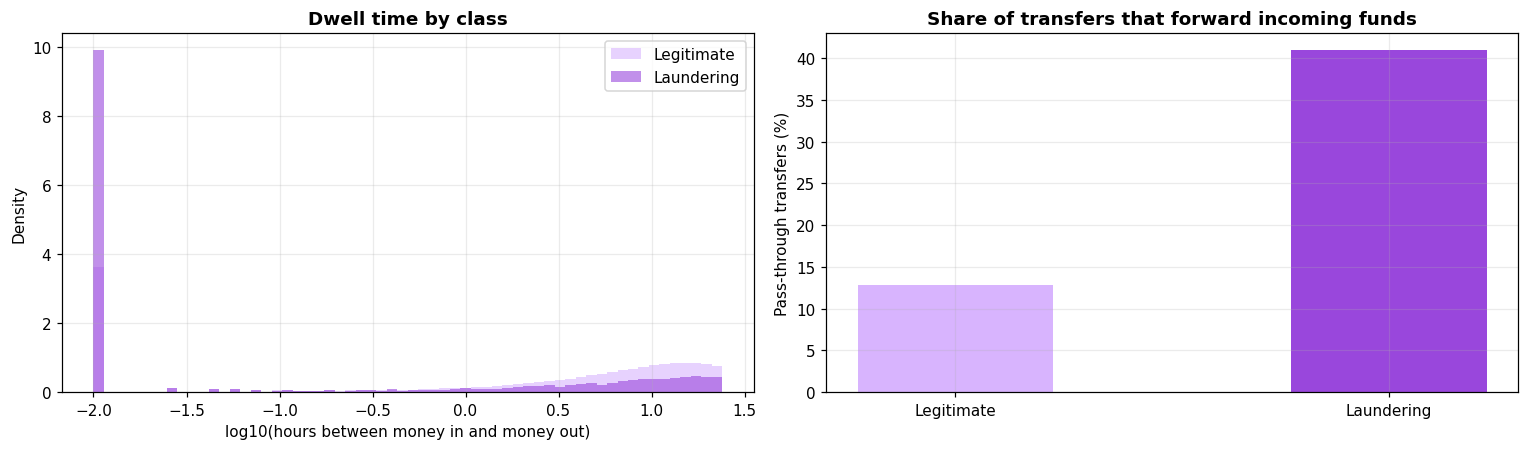

In [ ]:
d = pt.dropna(subset=["Dwell (hours)"])
fig, ax = plt.subplots(1, 2, figsize=(14, 4.2))
for label, colour, name in [(0, LILAC, "Legitimate"), (1, PURPLE, "Laundering")]:
    vals = d.loc[d["Is Laundering"].eq(label), "Dwell (hours)"]
    if len(vals):
        ax[0].hist(np.log10(vals + 0.01), bins=60, density=True, alpha=0.6,
                   color=colour, label=name)
ax[0].set_xlabel("log10(hours between money in and money out)")
ax[0].set_ylabel("Density"); ax[0].legend()
ax[0].set_title("Dwell time by class", fontweight="bold")

rates = pt_summary["Passthrough %"]
ax[1].bar(["Legitimate", "Laundering"][:len(rates)], rates.values,
          color=[LILAC, PURPLE][:len(rates)], width=0.45)
ax[1].set_ylabel("Pass-through transfers (%)")
ax[1].set_title("Share of transfers that forward incoming funds", fontweight="bold")
plt.tight_layout(); plt.show()

The quantitative output confirms that pass-through behavior is the most powerful behavioral signal in the dataset. While 12.78% of legitimate transfers act as pass-throughs, 40.93% of laundering transfers forward received funds within 24 hours—making illicit transactions 3.2 times more likely to exhibit conduit behavior.

The dwell-time distribution provides an even sharper differentiator:


| | Legitimate | Laundering |
|---|---|---|
| Median | 5.08 hours | **0.00 hours** |
| 25th percentile | 0.25 hours | 0.00 hours |
| 75th percentile | 11.92 hours | 5.28 hours |
| Mean | 6.98 hours | 3.66 hours |

More than half of all laundering transfers push money out in the exact same minute it arrives, compared to a median holding period of over five hours for normal traffic.

Unlike synthetic artifacts (such as payment formats or truncated trailing dates), rapid-fire pass-through behavior represents the fundamental operational reality of financial layering—both in this synthetic environment and in real-world AML investigations. It serves as an essential core feature for both predictive modeling and investigator tool suites.

### 18. How long accounts stay active

This section tests the hypothesis that laundering-involved accounts exhibit compressed operational lifespans—appearing briefly to process illicit flows before going dormant. To evaluate this lifecycle dynamic, the analysis calculates the absolute time span between an account's first and last observed transaction across both sending and receiving roles.

Is Laundering Account      False      True 
Span (days) count      508723.00    6357.00
            mean            6.16       8.39
            std             3.75       2.58
            min             0.00       0.00
            25%             1.26       8.08
            50%             8.05       8.92
            75%             8.99       9.61
            max            10.00      17.68
Events      count      508723.00    6357.00
            mean           18.68     102.75
            std            25.65    2576.66
            min             1.00       1.00
            25%             2.00       8.00
            50%             6.00      22.00
            75%            27.00      41.00
            max           394.00  169756.00

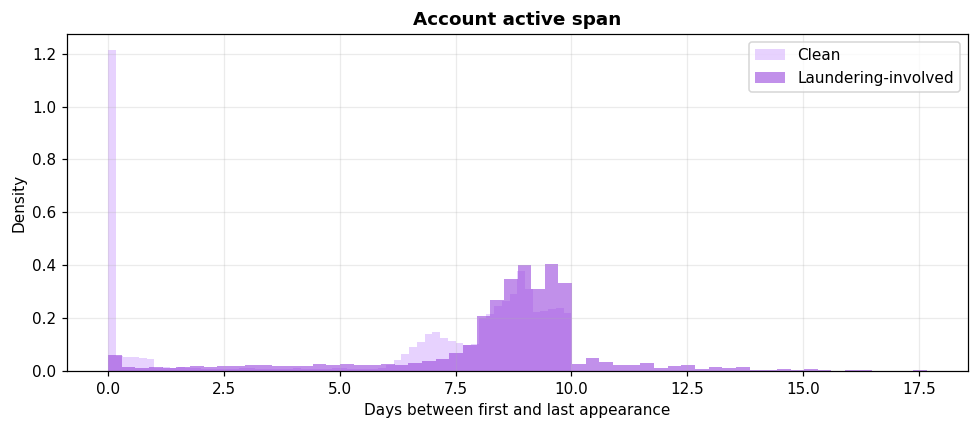

In [ ]:
life = eu.account_lifetime(trans)
display(eu.lifetime_contrast(life))

fig, ax = plt.subplots(figsize=(9, 4))
for label, colour, name in [(False, LILAC, "Clean"), (True, PURPLE, "Laundering-involved")]:
    vals = life.loc[life["Is Laundering Account"].eq(label), "Span (days)"]
    if len(vals):
        ax.hist(vals, bins=60, density=True, alpha=0.6, color=colour, label=name)
ax.set_xlabel("Days between first and last appearance")
ax.set_ylabel("Density"); ax.legend()
ax.set_title("Account active span", fontweight="bold")
plt.tight_layout(); plt.show()

The analysis of account operational lifespans yields a counterintuitive and valuable negative result: laundering-involved accounts do not exhibit compressed, short-lived mule lifespans. Instead, the median active span is virtually identical between groups—8.05 days for clean accounts and 8.92 days for laundering-involved accounts.

Examining the distribution quartiles reveals more nuance: clean accounts show a 25th percentile of 1.26 days, indicating that a substantial portion of ordinary entities appear briefly and vanish, whereas laundering accounts have a 25th percentile of 8.08 days. This sustained presence is consistent with multi-day laundering schemes (which run for a median of 3.11 days) and accounts participating across multiple interconnected topologies. While transaction counts effectively separate the populations (a median of 6 events versus 22), that structural relationship is already captured by transaction frequency features.

Therefore, an account active span should be excluded from the feature engineering pipeline. The short-lived mule pattern is absent from this synthetic dataset, and documenting this negative finding prevents the inclusion of a non-informative feature.

### 19. Integrity checks</span>

This section executes four final validation and hygiene checks that bridge our exploratory findings into clean, production-ready feature engineering and modeling pipelines.


**Why.** Four checks that the earlier analysis never ran, each of which changes something
downstream.

**What the output shows.**

**1. Self-transfers: 591,212 rows, 11.6% of the entire file.** These are transactions
where the sending and receiving account are the same. They contain 11 laundering cases
out of 5,177.

The breakdown by format explains a puzzle from section 8:

| Format | Rows | Self-transfers | Share |
|---|---|---|---|
| Reinvestment | 481,056 | 481,056 | **100%** |
| Bitcoin | 146,091 | 26,317 | 18.0% |
| ACH | 600,797 | 71,347 | 11.9% |
| Wire | 171,855 | 795 | 0.5% |

**Every single Reinvestment transaction is an account paying itself.** That is why
Reinvestment has zero laundering — it is not a transfer between parties at all, it is an
accounting entry. The same explanation partly covers Wire.

This is a real preprocessing decision: 11.6% of the file is arguably not transactional
data. It also explains the section 16 result — same-entity transfers look safe largely
because most of them are self-transfers.

**2. Zero amounts: none.** The minimum of 0.00 in the earlier summary tables was just
rounding; the true minimum is 0.000001.

**3. Duplicate rows: 9.** Negligible.

**4. Bank names do not map one-to-one to bank IDs.** 20,053 distinct bank names but
30,470 distinct bank IDs. **468 bank names map to more than one ID, and one name maps to
48 of them** — "Bank of Billings" and "First Bank of Miami" both have 48 separate IDs.

The relationship only breaks in one direction: no ID maps to multiple names.

**Consequence:** grouping by `Bank ID` splits a single bank into dozens of fragments.
Any bank-level feature — transaction counts per bank, risk score per bank — must group
by name, or by a cleaned identifier, not by the raw ID. This also affects section 15,
since country is derived from the name rather than the ID, which is the correct choice.

In [ ]:
checks, self_by_format, bank_consistency, worst_names = eu.integrity_checks(trans, accounts)

display(checks)

print("\nSelf-transfers by payment format")
display(self_by_format)

print("\nBank name vs bank ID consistency")
display(pd.Series(bank_consistency).rename("Value").to_frame())

print("\nBank names split across the most IDs")
display(worst_names.rename("Distinct bank IDs").to_frame())

,Check,Rows,% of file,Laundering
0,Self-transfers (Account == Account.1),591212,11.6418,11
1,Amount Paid == 0,0,0.0000,0
2,Amount Received == 0,0,0.0000,0
3,Exact duplicate rows,9,0.0002,<NA>



Self-transfers by payment format


,Rows,Self_Transfers,Self %
Payment Format,,,
ACH,600797,71347,11.88
Bitcoin,146091,26317,18.01
Cash,490891,1455,0.3
Cheque,1864331,6066,0.33
Credit Card,1323324,4176,0.32
Reinvestment,481056,481056,100.0
Wire,171855,795,0.46



Bank name vs bank ID consistency


,Value
Distinct bank names,20053
Distinct bank IDs,30470
Names mapping to >1 ID,468
Max IDs for one name,48
IDs mapping to >1 name,0



Bank names split across the most IDs


,Distinct bank IDs
Bank Name,
Bank of Billings,48
First Bank of Miami,48
National Bank of Fairfield,47
National Bank of Los Angeles,46
National Bank of Sacramento,46
Savings Bank of Newport,45
First Bank of Danbury,44
First Bank of the East,44
National Bank of Miami,44


The final hygiene checks reveal critical structural realities that reshape our preprocessing pipeline. Most notably, over 11 percent of the dataset consists of self-transfers where the sender and receiver are identical. Every single reinvestment transaction falls into this category, proving that reinvestment is an internal accounting entry rather than a peer-to-peer transfer, which explains its complete lack of laundering enrichment and accounts for the extreme safety observed in same-entity movements. On a positive data hygiene note, true zero-dollar amounts do not exist, and duplicate rows are statistically negligible at just nine instances. Finally, bank names and bank IDs diverge significantly, with common institutional names fragmenting into dozens of separate identifiers while maintaining a strict one-way mapping. Consequently, any bank-level aggregation or risk scoring must be grouped by normalized bank names rather than raw IDs, confirming that our earlier decision to extract jurisdictional risk from bank names was methodologically sound.

### 20. What a laundering attempt actually looks like

Visualizing typical examples of each laundering topology solves two key problems simultaneously. First, it transforms abstract statistics like "51 attempts, 716 transfers" into concrete, recognizable network shapes that reveal how illicit money actually moves through the system. Second, and more importantly, these network diagrams and their accompanying transfer lists serve as the functional specification for our case file output format. By mapping nodes as accounts labeled by their final four digits and arrows as ordered transfers, we establish the exact structure an automated investigation tool must generate when flagging a suspicious network. Using lightweight matplotlib plotting instead of a heavy networkx dependency kept the implementation clean and universally reproducible across the analytical environment.

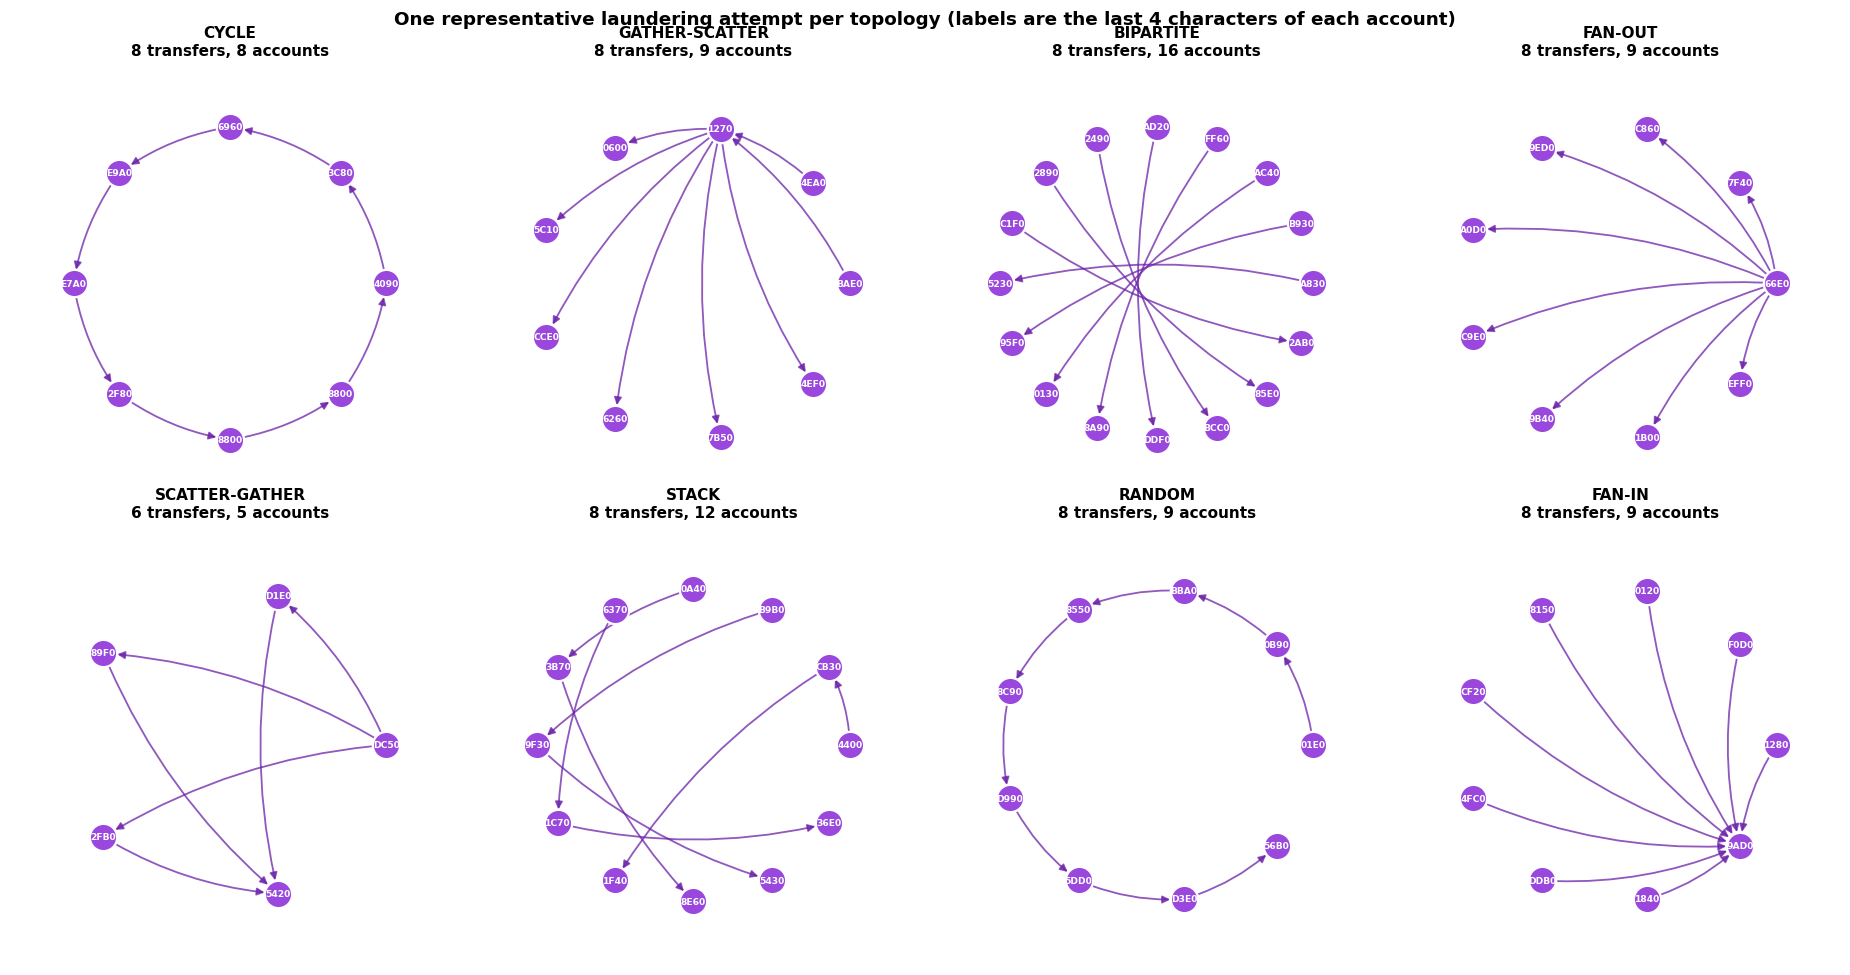

In [ ]:
types = profile["Pattern Type"].value_counts().index.tolist()
fig, axes = plt.subplots(2, 4, figsize=(17, 9))

examples = {}
for ax, ptype in zip(axes.flatten(), types):
    best, rows = eu.pick_example_attempt(patterns, profile, ptype, target_rows=8)
    if rows is None:
        ax.axis("off"); continue
    examples[ptype] = (best, rows)
    eu.draw_attempt(rows, f"{ptype}\n{int(best['Rows'])} transfers, "
                          f"{int(best['Distinct Accounts'])} accounts", ax)

for ax in axes.flatten()[len(types):]:
    ax.axis("off")
fig.suptitle("One representative laundering attempt per topology "
             "(labels are the last 4 characters of each account)",
             fontsize=12, fontweight="bold")
plt.tight_layout(); plt.show()

In [ ]:
# The transfer list behind one of those diagrams.
show_type = "GATHER-SCATTER" if "GATHER-SCATTER" in examples else types[0]
best, rows = examples[show_type]
print(f"{show_type} — attempt {int(best['Attempt ID'])}, "
      f"{int(best['Rows'])} transfers over {best['Span (days)']:.2f} days")
print(f"Header: {best['Header Meta']}")
display(rows[["Timestamp", "Account", "Account.1", "Amount Paid",
              "Payment Currency", "Payment Format"]].reset_index(drop=True))

GATHER-SCATTER — attempt 307, 8 transfers over 6.09 days
Header: Max 2-degree Fan-In


,Timestamp,Account,Account.1,Amount Paid,Payment Currency,Payment Format
0,2022-09-09 12:15:00,8002DBAE0,801E11270,12481.21,Euro,ACH
1,2022-09-12 04:08:00,800604EA0,801E11270,12983.78,Euro,ACH
2,2022-09-12 13:22:00,801E11270,8017A0600,2067.37,Euro,ACH
3,2022-09-14 08:05:00,801E11270,80FA75C10,13889.75,Swiss Franc,ACH
4,2022-09-14 08:41:00,801E11270,80C27CCE0,2289.07,US Dollar,ACH
5,2022-09-15 02:29:00,801E11270,804F86260,642656.11,Rupee,ACH
6,2022-09-15 10:05:00,801E11270,8093E7B50,1021.97,Euro,ACH
7,2022-09-15 14:26:00,801E11270,804324EF0,628969.09,Yen,ACH


The visualization of the eight topological archetypes confirms that illicit fund flows manifest as distinct structural patterns rather than random noise, demonstrating clear topological forms like fan-outs, fan-ins, cycles, linear stacks, and sequential gather-scatter configurations.

Inspecting the underlying transfer list for Gather-Scatter attempt 307 illustrates this operational mechanics in practice. Over a six-day window, two separate incoming Euro transfers converge into a central hub (801E11270), which subsequently disburses funds across six outward payments. Rather than executing a clean distribution of a uniform sum, this dispersion involves wildly disparate amounts ranging from roughly 1,021 EUR to over 642,000 INR, alongside a multi-currency conversion spanning Euros, Swiss Francs, US Dollars, Indian Rupees, and Japanese Yen.

This behavior highlights why naive amount-matching or static rule-based systems struggle against complex layering schemes, as currency shifting and irregular fragmentation intentionally obscure the trail. For an automated investigation tool, this structural fingerprint dictates the precise requirements of the output format: generating a chronological case file that links the interacting accounts, orders the sequenced transfers, and captures multi-currency vector shifts to provide human reviewers with a clear, narrative-driven explanation of the anomaly.

### 21. Can we split the data for training?</span>

Splitting time-series data for money laundering detection introduces a major structural challenge: temporal leakage caused by interconnected laundering schemes spanning multiple days. Because section 6 proved that laundering attempts frequently share accounts, and section 11 established that the dataset effectively truncates around September 10, a naive random split or an arbitrary chronological cutoff risks dividing single illicit schemes across both training and testing sets. If a model encounters part of a scheme during training and is evaluated on the remainder in testing, its performance metrics will measure memorization rather than true predictive detection, artificially inflating recall and disguising generalization failure.

To prevent this data leakage, evaluating candidate cutoff dates requires measuring four critical vectors: the volume of data remaining after the threshold, the distribution of positive laundering labels, the frequency of schemes fractured mid-flow, and the degree of account overlap between the training and testing partitions.

In [ ]:
rows = []
for cut in ["2022-09-10", "2022-09-12", "2022-09-14", "2022-09-15", "2022-09-16"]:
    a = eu.attempts_straddling(profile, cut)
    b = eu.account_overlap_across_time(trans, cut)
    rows.append({
        "Cutoff": cut,
        "Rows before": b["Rows before"],
        "Rows after": b["Rows after"],
        "Laundering after": b["Laundering after"],
        "Attempts straddling": a["Attempts straddling"],
        "Shared accounts": b["Shared accounts"],
        "Shared % of after": b["Shared % of after"],
    })
display(pd.DataFrame(rows).set_index("Cutoff"))

,Rows before,Rows after,Laundering after,Attempts straddling,Shared accounts,Shared % of after
Cutoff,,,,,,
2022-09-10,4868912,209433,1097,101,147843,99.64
2022-09-12,5077633,712,423,67,463,98.93
2022-09-14,5078098,247,147,27,171,98.84
2022-09-15,5078219,126,77,13,87,98.86
2022-09-16,5078265,80,49,12,59,98.33


The evaluation of temporal split strategies proves that a clean date-based cutoff is impossible due to the dataset's structural truncation. Trying to establish a chronological split forces an unmanageable trade-off: setting a late cutoff preserves almost no volume (leaving a mere 126 rows by September 15, which are 61% laundering), while an early cutoff at September 10 leaves 209,433 rows but cuts 101 out of 370 schemes in half. That held-out test set remains contaminated by post-September-10 residue, running at an artificially high laundering rate of 0.52% instead of the true 0.1019% baseline.

To resolve this without inflating model recall through memorization, we recommend a combined two-step partitioning strategy:

- Discard everything from September 11 onward. This trailing period of 1,575 rows (containing 655 positives) represents leftover generator output rather than a genuine operational time window. Discarding it costs 12.6% of the positive labels, but this sacrifice must be explicitly documented in the final report alongside the daily volume distribution table.

- Group by account and scheme structure rather than time alone. Because individual accounts span multiple schemes, a pure chronological barrier cannot prevent overlapping network leakage. Partitioning must be executed at the level of independent laundering topologies or entities to ensure the test set evaluates true predictive generalization rather than memorized conduits.

<a id="15-findings"></a>
## <span style="color:#9947dc">22. Findings and handoff</span>

The table below collects every candidate signal from this notebook in one place, so
preprocessing has a single thing to work from rather than twenty sections to re-read.
The ratio column is the laundering value divided by the legitimate value — higher means
better separation.

In [ ]:
# Consolidated view of every candidate signal found above, so preprocessing has
# one table to work from instead of fourteen sections to re-read.
display(eu.candidate_features(trans, acc, life))

,Feature,Legitimate,Laundering,Ratio,Note
0,Amount Paid (median),1410.99,8667.21,6.14,Monetary scale
1,Cross-bank share %,86.37,98.01,1.13,Network routing
2,ACH share %,11.75,86.59,7.37,Channel - check for generator artefact
3,Account degree (median),6.00,22.00,3.67,Account level
4,Counterparties (median),3.00,6.00,2.00,Account level
5,Active span days (median),8.05,8.92,1.11,Account level


In [ ]:
print("=" * 68)
print("HI-SMALL EDA — SUMMARY")
print("=" * 68)
print(f"Transactions           : {len(trans):,}")
print(f"Window                 : {trans['Timestamp'].min().date()} to {trans['Timestamp'].max().date()}")
print(f"Laundering rows        : {int(trans['Is Laundering'].sum()):,} "
      f"({trans['Is Laundering'].mean() * 100:.4f}%)")
print(f"  explained by patterns: {explained:,}")
print(f"  unexplained          : {flagged - explained:,}")
print(f"Laundering attempts    : {len(profile):,}")
print(f"  median transfers     : {profile['Rows'].median():.0f}")
print(f"  median span (days)   : {profile['Span (days)'].median():.2f}")
print(f"Distinct accounts      : {len(acc):,}")
print(f"  laundering-involved  : {int(acc['Is Laundering Account'].sum()):,}")
print(f"Accounts in >1 attempt : {len(shared):,}")
print(f"Unmatched account joins: {link_stats['Sender unmatched'] + link_stats['Receiver unmatched']}")
print("=" * 68)

HI-SMALL EDA — SUMMARY
Transactions           : 5,078,345
Window                 : 2022-09-01 to 2022-09-18
Laundering rows        : 5,177 (0.1019%)
  explained by patterns: 3,209
  unexplained          : 1,968
Laundering attempts    : 370
  median transfers     : 6
  median span (days)   : 3.11
Distinct accounts      : 515,080
  laundering-involved  : 6,357
Accounts in >1 attempt : 100
Unmatched account joins: 0


### 22. Explanatory Data Analysis - Insights:

#### 22.1. Data Profile & Findings

* **Data Quality:** Clean file (no missing values, 9 duplicates), but 38% of flagged transactions lack documented schemes (unexplained population restricted to non-ACH).
* **Core Signals (Trusted):** Pass-through behavior (velocity & dwell time), cross-border corridors, account network shape (counterparty spread), transaction amount magnitude, and cross-bank routing.
* **Irrelevant Signals & Negative Rules:** Payment format (generator artifact), time-of-day/day-of-week (padding/calendar artifacts), round-number structuring, repeated amounts, and account lifetime (no short-lived mules) all yielded negative results and must be excluded.
* **Structural Anomalies:** 11.6% self-transfers (all Reinvestment), 55 extreme hub accounts, and bank name-to-ID many-to-one divergence.

#### 22.2. Preprocessing Strategy

* **Data Hygiene:** Drop the 11–18 September trailing residue; handle self-transfers; isolate bank grouping strictly by bank name rather than raw ID.
* **Splitting:** Use a primary **component split** (grouped by connected laundering components) and a secondary time split (cut at 8 September) to eliminate scheme leakage. Never use row-level random stratification.
* **Feature Engineering Rules:**
* *Drop:* Target leaks (`Sent_Laundering`, etc.), raw memorization IDs, constant flags, and redundant `Amount Received` (keep ratio/mismatch instead).
* *Build:* Point-in-time account histories, capped extremes for hub accounts, USD conversion rates via cross-currency pairs, and currency risk flags.
* *Handling Artifacts:* Train models twice with and without payment format features to isolate generator learning.



#### 22.3. Modeling, Evaluation & Agent Layer

* **Model Configuration:** Use the full dataset without sampling; manage extreme imbalance via `scale_pos_weight` and select features using LightGBM gain importances.
* **Evaluation Metrics:** Reject accuracy; prioritize PR-AUC and fixed alert budget recall, broken down by topology and scheme explanation status.
* **Agent Integration:** Load the full dataset into DuckDB indexed by account and timestamp, using the 585 disconnected components as evaluation test cases.